In [3]:
import os
import pathlib
import sys
import socket

hostname = socket.gethostname()
print(hostname)


abs_path = str(pathlib.Path(hostname).parent.absolute())
WORKDIR = abs_path[:- (len(abs_path.split('/')[-2] + abs_path.split('/')[-1])+1)]



if "mimi" in hostname or "pingo" in hostname or "ivan" in hostname:
    DATA_DIR = "/mn/vann/franzihe/"
    FIG_DIR = "/uio/kant/geo-geofag-u1/franzihe/Documents/Figures/ANX_obs_daily/final/"


INPUT_DATA_DIR = os.path.join(DATA_DIR, 'input')
OUTPUT_DATA_DIR = os.path.join(DATA_DIR, 'output')
UTILS_DIR = os.path.join(WORKDIR, 'utils')

sys.path.append(UTILS_DIR)

# make figure directory to put in reflectivity processed data
try:
    new_dir = pathlib.Path(FIG_DIR)
    new_dir.mkdir(parents=True, exist_ok=True)
except OSError:
    pass

nc_dir = os.path.join(OUTPUT_DATA_DIR, 'ANX_obs')


ivan.uio.no


In [4]:
# supress warnings
import warnings
warnings.filterwarnings('ignore') # don't output warnings

# import packages
from imports import(xr, glob, plt, np, DateFormatter, datetime, cm, pd, da, IMProToo,LinearSegmentedColormap, BoundaryNorm, time, curve_fit, sns, set_context, linregress, pi, Rectangle, HandlerTuple, Line2D, ListedColormap, Patch)
# from matplotlib.collections import PathCollection
import functions as fct
version = IMProToo.__version__


In [5]:
# plot cosmetics
set_context('paper', rc={"lines.linewidth": 2}, font_scale=1.5, )

In [6]:
# reload imports
%load_ext autoreload
%autoreload 2

In [7]:
site = 'ANX'
year = '2023'

### Files to read in

In [ ]:
ds_23 = xr.open_mfdataset(sorted(glob(os.path.join(nc_dir, f'10min_filled_obs_hatpro_airport_WD_WS_T_{site}_{year}*.nc'))))[['Ze', 'W', 'height', 'air_temperature', 'precipitation', 'wind_direction', 'wind_speed', 'Matrosov_a_400', 'Bracci_a_400', 'Nakai_a_400', 'Nakai_g_400', 'Pu_g_400','Ze_400m']]
ds_23 = ds_23.rename_vars({'precipitation':'Geonor'})

#### Plot the distribution of 1-minute reflectivity values at 400 m (in dBZ) over the full campaign

x-axis --> reflectivity bins (dBZ)
y-axis --> number of minutes falling in each bin

==> each count = one minute of radar data

**Answers: Which Z values dominate my retrievals?**

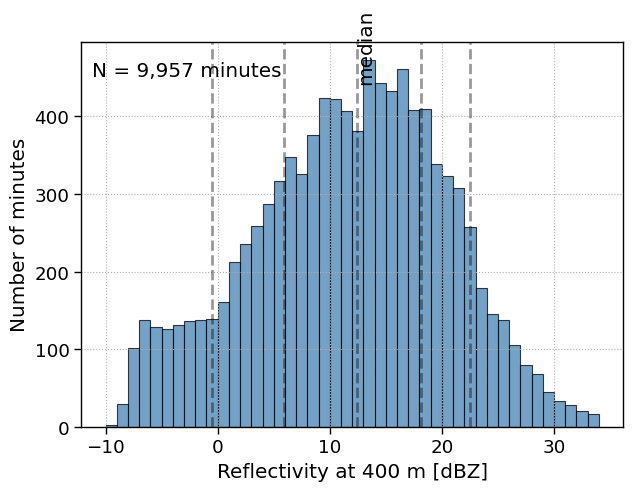

In [9]:
# clea data
Z = ds_23['Ze_400m'].values
# keep only finit values
Z = Z[np.isfinite(Z)]
# remove very low reflectivties
Z = Z[Z > -10.]


fig, ax = plt.subplots(1,1, figsize=(7,5))
ax.hist(Z, bins=np.arange(-10,35,1), # 1 dB bins 
        color='steelblue',
        edgecolor='black',
        alpha=0.75)

# for z in [-5, 0, 5, 10]: # sensitivity of retrieval
#     ax.axvline(z, color='k', ls='--', alpha=0.4)

q = np.percentile(Z, [10, 25, 50, 75, 90])
for z in q:
        ax.axvline(z, color='k', ls='--', alpha=0.4)

ax.text(q[2], ax.get_ylim()[1]*0.9, 'median', rotation=90)


ax.text(0.02, 0.95,
        f'N = {len(Z):,} minutes',
        transform=ax.transAxes,
        va='top')


ax.set_xlabel('Reflectivity at 400 m [dBZ]')
ax.set_ylabel('Number of minutes')
ax.grid(True, ls=':')

#### Where snowfall contribution peaks

In [10]:
# # weight by snowfall rate
# weights = df['rate_mm_h'].values
# Zf = df['Ze_400m'].values

# bins = np.arange(-10, 35, 1)
# bin_centers = 0.5 * (bins[:-1] + bins[1:])

# S_sum, _ = np.histogram(Zf, bins=bins, weights=weights)

# ax.plot(bin_centers, S_sum / S_sum.sum(), color='red')
# ax.set_ylabel('Fraction of total snowfall')


In [11]:
# ds_23['W'] = ds_23['W'].where(ds_23['W'] <= 7., other=np.nan)
# ds_23['W'] = ds_23['W'].where(ds_23['W'] > -7., other=np.nan)

In [12]:
df = dict()
df_nearest = dict()
df_no_sf_class = dict()
vars_to_keep = ['Geonor', 'air_temperature', 'wind_direction', 'wind_speed', 'snowflake_class_name', 'rate_mm_h', 
                'Matrosov_a_400', 'Bracci_a_400', 'Nakai_a_400', 'Nakai_g_400', 'Pu_g_400',
                'Matrosov_a_400_mm_h', 'Bracci_a_400_mm_h', 'Nakai_a_400_mm_h', 'Nakai_g_400_mm_h', 'Pu_g_400_mm_h', 'start_time', 'Ze_400m']

open_ds = xr.open_mfdataset(sorted(glob(os.path.join(OUTPUT_DATA_DIR, 'ANX_obs', f'Z_S_2Tm_WD_WS_class_precip_event_dt_offset_{site}_{year}.nc'))))
df['event_offset'] = open_ds[vars_to_keep].to_dataframe()

open_ds_nearest = xr.open_mfdataset(sorted(glob(os.path.join(OUTPUT_DATA_DIR, 'ANX_obs', f'Z_S_2Tm_WD_WS_nearest_class_precip_event_dt_offset_{site}_{year}.nc'))))
df_nearest['event_offset'] = open_ds_nearest[vars_to_keep].to_dataframe()
open_ds_nearest.close()

open_ds_no_sf_class = xr.open_mfdataset(sorted(glob(os.path.join(OUTPUT_DATA_DIR, 'ANX_obs', f"Z_S_2Tm_WD_WS_precip_event_{site}_{year}.nc"))))
df_no_sf_class['event_offset'] = open_ds_no_sf_class[['Geonor', 'air_temperature', 'wind_direction', 'rate_mm_h', 
                                                     'Matrosov_a_400', 'Bracci_a_400', 'Nakai_a_400', 'Nakai_g_400', 'Pu_g_400']].to_dataframe()

for dt in ['1min', '5min', '10min', '30min', '60min']:
    open_ds = xr.open_mfdataset(sorted(glob(os.path.join(OUTPUT_DATA_DIR, 'ANX_obs', f'Z_S_2Tm_WD_WS_class_precip_{dt}_dt_offset_{site}_{year}.nc'))))
    df[dt] = open_ds[vars_to_keep].to_dataframe()


    open_ds_nearest = xr.open_mfdataset(sorted(glob(os.path.join(OUTPUT_DATA_DIR, 'ANX_obs', f"Z_S_2Tm_WD_WS_nearest_class_precip_{dt}_dt_offset_{site}_{year}.nc"))))
    df_nearest[dt] = open_ds_nearest[vars_to_keep].to_dataframe()
    open_ds_nearest.close()

    open_ds_no_sf_class = xr.open_mfdataset(sorted(glob(os.path.join(OUTPUT_DATA_DIR, 'ANX_obs', f"Z_S_2Tm_WD_WS_precip_{dt}_dt_{site}_{year}.nc"))))
    df_no_sf_class[dt] = open_ds_no_sf_class[['Geonor', 'air_temperature', 'wind_direction', 'wind_speed', 'rate_mm_h', 
                                             'Matrosov_a_400', 'Bracci_a_400', 'Nakai_a_400', 'Nakai_g_400', 'Pu_g_400']].to_dataframe()
    

In [13]:
open_ds_nearest

<xarray.Dataset> Size: 475kB
Dimensions:                    (time: 190, time_frame: 2, bin: 24)
Coordinates:
  * time                       (time) datetime64[ns] 2kB 2023-02-19T09:00:00 ...
  * bin                        (bin) float64 192B 0.0003317 ... 0.02738
    dD                         (bin) float64 192B dask.array<chunksize=(24,), meta=np.ndarray>
  * time_frame                 (time_frame) <U13 104B 'dt' 'seasonal_mean'
Data variables: (12/73)
    shifted_time_end           (time) datetime64[ns] 2kB dask.array<chunksize=(190,), meta=np.ndarray>
    Geonor                     (time) float64 2kB dask.array<chunksize=(190,), meta=np.ndarray>
    air_temperature            (time) float64 2kB dask.array<chunksize=(190,), meta=np.ndarray>
    wind_direction             (time) float64 2kB dask.array<chunksize=(190,), meta=np.ndarray>
    wind_speed                 (time) float64 2kB dask.array<chunksize=(190,), meta=np.ndarray>
    snowflake_class_name       (time) <U9 7kB dask.array<chunksize=(190,), meta=np.ndarray>
    ...                         ...
    Matrosov_from_ze_sum_1000  (time) float64 2kB dask.array<chunksize=(190,), meta=np.ndarray>
    counts                     (time_frame, time, bin) float64 73kB dask.array<chunksize=(2, 190, 24), meta=np.ndarray>
    v_bin_m_s                  (time_frame, time, bin) float64 73kB dask.array<chunksize=(2, 190, 24), meta=np.ndarray>
    m_bin_kg                   (time_frame, time, bin) float64 73kB dask.array<chunksize=(2, 190, 24), meta=np.ndarray>
    N_bin_m3                   (time_frame, time, bin) float64 73kB dask.array<chunksize=(2, 190, 24), meta=np.ndarray>
    n_per_m                    (time_frame, time, bin) float64 73kB dask.array<chunksize=(2, 190, 24), meta=np.ndarray>

### Filter the dominant snowflake class and create individual dataframes

In [14]:
aggregate = {}
graupel = {}
mixed = {}
pristine = {}
sf_class_dict = {}
for dt in ['event_offset', '1min', '5min', '10min', '30min', '60min']:
    aggregate[dt]   = df[dt][df[dt]['snowflake_class_name'] == 'aggregate']
    graupel[dt]     = df[dt][df[dt]['snowflake_class_name'] == 'graupel']
    mixed[dt]       = df[dt][df[dt]['snowflake_class_name'] == 'mixed']
    pristine[dt]    = df[dt][df[dt]['snowflake_class_name'] == 'pristine']

    sf_class_dict[dt] = {'aggregate':aggregate[dt], 'graupel':graupel[dt], 'mixed':mixed[dt], 'pristine':pristine[dt]}

In [15]:
aggregate_nearest = {}
graupel_nearest = {}
mixed_nearest = {}
pristine_nearest = {}
sf_class_dict_nearest = {}
for dt in ['event_offset', '1min', '5min', '10min', '30min', '60min']:
    aggregate_nearest[dt] = df_nearest[dt][df_nearest[dt]['snowflake_class_name'] == 'aggregate']
    graupel_nearest[dt] = df_nearest[dt][df_nearest[dt]['snowflake_class_name'] == 'graupel']
    mixed_nearest[dt] = df_nearest[dt][df_nearest[dt]['snowflake_class_name'] == 'mixed']
    pristine_nearest[dt] = df_nearest[dt][df_nearest[dt]['snowflake_class_name'] == 'pristine']
    
    sf_class_dict_nearest[dt] = {'aggregate':aggregate_nearest[dt], 'graupel':graupel_nearest[dt], 'mixed':mixed_nearest[dt], 'pristine':pristine_nearest[dt]}

In [16]:
cmap = cm.managua  # define the colormap
# extract all colors from the colormap
cmaplist = [cmap(i) for i in range(cmap.N)]
# create the new map
custom_cmap = LinearSegmentedColormap.from_list(
'Custom cmap', cmaplist, 7) # cmap.N

colors = {'Geonor': [custom_cmap(3), 'Geonor (obs)', 'solid', ''],
          'Matrosov_a_400': [custom_cmap(1), "Matrosov (2007): Aggregate", 'solid', '*'],
          'Bracci_a_400': [custom_cmap(0), "Bracci et al. (2022): Aggregate", 'dotted', '*'],
          'Nakai_a_400': [custom_cmap(2), "Nakai et al. (2022): Aggregate", 'dashed', '*'],
          'Nakai_g_400': [custom_cmap(4), "Nakai et al. (2022): Graupel", 'dashed', '^'],
          'Pu_g_400': [custom_cmap(5), "Pu et al. (2020): Graupel", 'dotted', '^']}

legend_labels = [
    colors['Geonor'][1],
    colors['Matrosov_a_400'][1],
    colors['Bracci_a_400'][1],
    colors['Nakai_a_400'][1],
    colors['Nakai_g_400'][1],
    colors['Pu_g_400'][1]
]

# create proxy artists
geonor_line = Line2D([0],[0], linestyle=colors['Geonor'][2], color=colors['Geonor'][0])

matro_line = Line2D([0],[0], linestyle=colors['Matrosov_a_400'][2], color=colors['Matrosov_a_400'][0])
matro_mark = Line2D([0],[0], marker=colors['Matrosov_a_400'][3], linestyle='None',
                    color=colors['Matrosov_a_400'][0], markersize=12)

bracci_line = Line2D([0],[0], linestyle=colors['Bracci_a_400'][2], color=colors['Bracci_a_400'][0])
bracci_mark = Line2D([0],[0], marker=colors['Bracci_a_400'][3], linestyle='None', 
                     color=colors['Bracci_a_400'][0], markersize=12)

nakaiA_line = Line2D([0],[0], linestyle=colors['Nakai_a_400'][2], color=colors['Nakai_a_400'][0])
nakaiA_mark = Line2D([0],[0], marker=colors['Nakai_a_400'][3], linestyle='None',
                     color=colors['Nakai_a_400'][0], markersize=12)

nakaiG_line = Line2D([0],[0], linestyle=colors['Nakai_g_400'][2], color=colors['Nakai_g_400'][0])
nakaiG_mark = Line2D([0],[0], marker=colors['Nakai_g_400'][3], linestyle='None',
                     color=colors['Nakai_g_400'][0], markersize=12)

Pu_line = Line2D([0],[0], linestyle=colors['Pu_g_400'][2], color=colors['Pu_g_400'][0])
Pu_mark = Line2D([0],[0], marker=colors['Pu_g_400'][3], linestyle='None',
                     color=colors['Pu_g_400'][0], markersize=12)


colors2 = {
    'Geonor_aggregate_graupel_only': [custom_cmap(3), 'Geonor (obs)', 'solid', ''],
    'Matrosov_Nakai': [custom_cmap(1), "Matrosov (2007), Nakai et al. (2022)", 'dashed', '*'],
    'Bracci_Nakai': [custom_cmap(0), "Bracci et al. (2022), Nakai et al. (2022)", 'dashed', '*'],
    'Nakai_Nakai': [custom_cmap(2), "Nakai et al. (2022), Nakai et al. (2022)", 'dashed', '*'],
    'Matrosov_Pu': [custom_cmap(1), "Matrosov (2007), Pu et al. (2020)", 'dotted', '*'],
    'Bracci_Pu': [custom_cmap(0), "Bracci et al. (2022), Pu et al. (2020)", 'dotted', '*'],
    'Nakai_Pu': [custom_cmap(2), "Nakai et al. (2022), Pu et al. (2020)", 'dotted', '*'],}

In [17]:
particle_classes = [('aggregate', 1), ('graupel', 2), ('mixed', 3), ('pristine', 4)]
markers = ['*', '^', 'h', 'o',]

In [18]:
# Colorbar layout parameters
cbar_left = 0.95
cbar_width = 0.015
cbar_height = 0.15
cbar_top = 0.75
cbar_step = 0.1075  # vertical space between cbar axes

# Reflectivity'
# Define your radar-style reflectivity levels (can match the image closely)
bounds  = np.array([0, 3.5, 7, 10.5, 14, 17.5, 21, 24.5, 28])
bounds = np.linspace(0, 28, 9)
bounds = np.linspace(0, 28, 17)
norm= fct.BoundaryNorm(boundaries=bounds, ncolors=256)  # hawaii_r has 256 levels
# Use Crameri colormap (hawaii_r)
cmap= cm.hawaii_r
cmap = cm.managua_r

### Dominant snowflake class name per day

In [19]:
dt = '1min'

In [20]:
snowflake_class_count = pd.concat([aggregate[dt]['snowflake_class_name'].groupby(aggregate[dt].index.date).count().rename('aggregate_count'), 
                                   graupel[dt]['snowflake_class_name'].groupby(graupel[dt].index.date).count().rename('graupel_count'),
                                   mixed[dt]['snowflake_class_name'].groupby(mixed[dt].index.date).count().rename('mixed_count'),
                                   pristine[dt]['snowflake_class_name'].groupby(pristine[dt].index.date).count().rename('pristine_count'),], axis=1)

pd.concat([snowflake_class_count.max(axis=0), snowflake_class_count.idxmax(axis=0), ], axis=1)

,0,1
aggregate_count,120.0,2023-02-23
graupel_count,276.0,2023-03-11
mixed_count,75.0,2023-03-03
pristine_count,12.0,2023-03-04


In [21]:
snowflake_class_count

,aggregate_count,graupel_count,mixed_count,pristine_count
2023-02-19,17.0,21,6.0,1.0
2023-02-21,56.0,7,6.0,NaN
2023-02-23,120.0,74,41.0,2.0
2023-02-24,58.0,104,29.0,5.0
2023-02-25,6.0,62,2.0,NaN
2023-03-01,1.0,5,1.0,NaN
2023-03-02,11.0,8,3.0,NaN
2023-03-03,59.0,134,75.0,2.0
2023-03-04,13.0,89,42.0,12.0
2023-03-05,37.0,96,31.0,10.0


In [22]:
snowflake_class_count = pd.concat([aggregate_nearest[dt]['snowflake_class_name'].groupby(aggregate_nearest[dt].index.date).count().rename('aggregate_count'), 
                                   graupel_nearest[dt]['snowflake_class_name'].groupby(graupel_nearest[dt].index.date).count().rename('graupel_count'),
                                   mixed_nearest[dt]['snowflake_class_name'].groupby(mixed_nearest[dt].index.date).count().rename('mixed_count'),
                                   pristine_nearest[dt]['snowflake_class_name'].groupby(pristine_nearest[dt].index.date).count().rename('pristine_count'),], axis=1)

pd.concat([snowflake_class_count.max(axis=0), snowflake_class_count.idxmax(axis=0), ], axis=1)

,0,1
aggregate_count,271.0,2023-03-11
graupel_count,720.0,2023-03-09
mixed_count,147.0,2023-03-12
pristine_count,104.0,2023-03-09


### Aggregate case: 2023-02-22 22:00 to 2023-02-23 16:00

In [23]:
date = '20230223'

day_start = pd.Timestamp(f"{date} 07:00:00")
# day_end = day_start + pd.Timedelta(hours=23, minutes=59)
day_end = day_start + pd.Timedelta(hours=1, minutes=30)
xmin = day_start + pd.Timedelta(hours=0)
xmax = day_start + pd.Timedelta(hours=1, minutes=30)

ds_day = ds_23.sel(time=slice(day_start, day_end))
dt = '1min'
df_day = df[dt].loc[slice(xmin, xmax)]


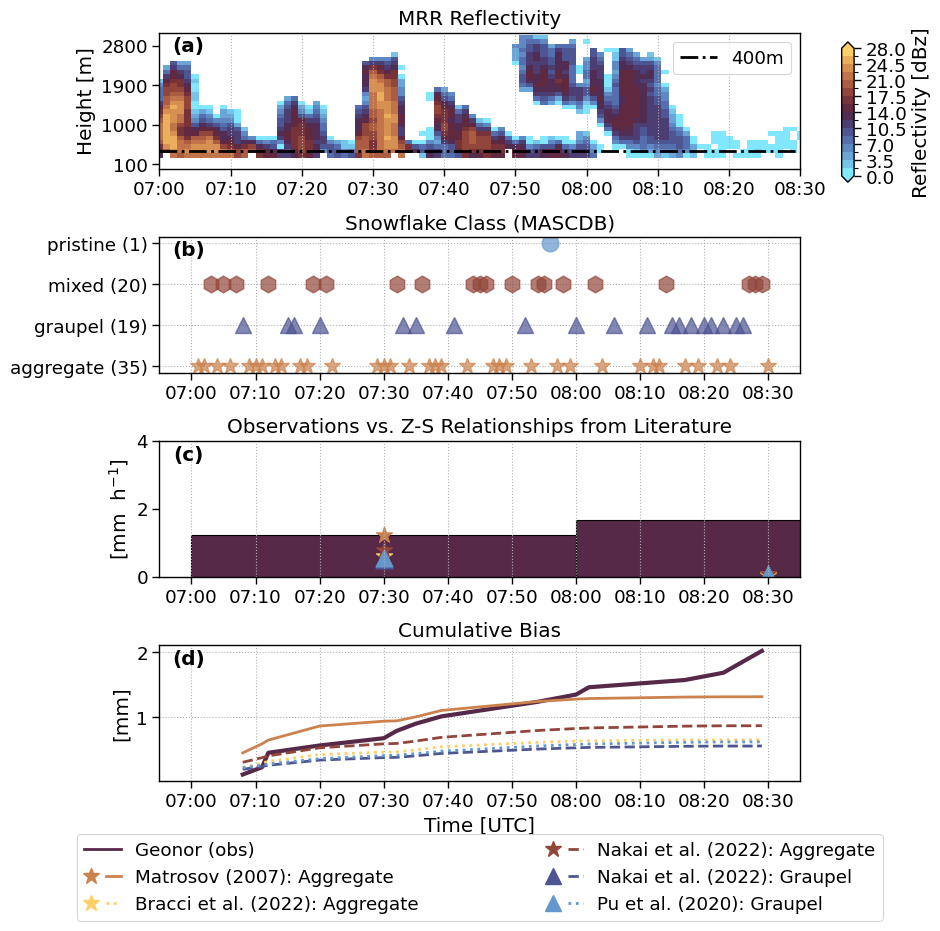

In [24]:
time_vals = fct.date2num(ds_day['time'].values)

# Define the region to highlight
x_start = xmin - pd.Timedelta(minutes=5)
x_end = xmax + pd.Timedelta(minutes=5)
y_start = 0.5 # slightly below the min y-value 
y_end = 30.5
x_width = x_end - x_start
y_height = y_end - y_start


fig, axsm = plt.subplots(4, 1, figsize=(8.27, 7.014/3*4), )#sharex=True, )
axs = axsm.flatten()

# a) 
fct.plot_pcolormesh_with_cbar(ax=axs[0], fig=fig, data=ds_day['Ze'].transpose('range','time'), x=time_vals, y=ds_day['range'], cmap=cmap, norm=norm, cbar_bounds=bounds[::2], cbar_label=f"Reflectivity [{ds_day['Ze'].attrs['units']}]", cbar_pos=[cbar_left, cbar_top -0 *cbar_step, cbar_width, cbar_height])
axs[0].hlines(4., ds_day.time.values[0], ds_day.time.values[-1], colors='k', linestyles='-.', label='400m')
axs[0].legend(loc='upper right')
axs[0].set_xlim([day_start, day_end])


# create a rectangle path
# rect = Rectangle((x_start, y_start), x_width, y_height, linewidth=2, edgecolor='k', linestyle='-', fill=False, )
# axs[0].add_patch(rect)

fct.format_range_axis(axs[0], ds_day)
# -----------

# b)
counts = []
for y_pos, (name, level) in enumerate(particle_classes, 1) :
    
    data = (df_day['snowflake_class_name'].where(df_day['snowflake_class_name'] == name)).dropna()
    counts.append(len(data))

    axs[1].plot(fct.date2num(data.index), 
                np.full(len(data.index), level),
                marker=markers[y_pos - 1], linestyle='None',
                color=fct.custom_colors[name], markersize=12, label=name, alpha=0.7)
    

axs[1].set_yticks(range(1,5))
axs[1].set_yticklabels([f"{name} ({cnt})" for (name, _), cnt in zip(particle_classes, counts)])
# axs[1].set_xlim([x_start, x_end])

# -----------

# c)
dt = "event_offset"
for var, var_c in colors.items():
    # df_sec = df[dt].loc[slice(xmin, xmax + pd.Timedelta(hours=1))]
    df_sec = df_nearest[dt].loc[slice(xmin, xmax + pd.Timedelta(hours=1))]
    precip = df_sec[var].resample('1H', closed='left', label='left').sum()
    if var == 'Geonor':
        axs[2].bar(precip.index+pd.Timedelta(minutes=30), precip, width=np.timedelta64(60,'m'), align='center', color=var_c[0], edgecolor='k', label=var_c[1])
    else: 
        axs[2].scatter(precip.index+pd.Timedelta(minutes=30), precip, marker=var_c[3], color=var_c[0], s=150, edgecolor=var_c[0])
axs[2].set_ylabel("[mm  h$^{-1}$]")
axs[2].set_ylim([0, 4])
# axs[2].set_xlim([x_start, x_end])


# -----------

# d)
for var, var_c in colors.items():
    # df_sec = df[dt].loc[slice(xmin, xmax)]
    # precip = df_day[var].fillna(0).cumsum()
    df_sec = df_nearest[dt].loc[slice(xmin, xmax)]
    precip = df_sec[var].fillna(0).cumsum()
    if var == 'Geonor':
        linewidth = 3
    else:
        linewidth = 2
    axs[3].plot(precip.index, precip, color=var_c[0], label=var_c[1], linestyle=var_c[2], linewidth=linewidth)
axs[3].set_ylabel("[mm]")
# axs[3].set_ylim([0, 4])
# axs[3].set_xlim([x_start, x_end])
# -----------

# pairing: either (marker,line) or (line,marker) depending on visual preference
legend_items = [
    geonor_line,
    (matro_mark, matro_line),
    (bracci_mark, bracci_line),
    (nakaiA_mark, nakaiA_line),
    (nakaiG_mark, nakaiG_line), 
    (Pu_mark, Pu_line)
]
bb = (fig.subplotpars.left -0.1, fig.subplotpars.bottom-0.15, 
fig.subplotpars.right-fig.subplotpars.left + 0.2,.1)

axs[3].legend(
    handles = legend_items,
    labels  = legend_labels,
    handler_map={tuple: HandlerTuple(ndivide=None)},
    bbox_to_anchor=bb, mode="expand", loc="lower left",
    ncol=2, borderaxespad=0., bbox_transform=fig.transFigure
)



date_form = DateFormatter("%H:%M")
for (i, ax), title in zip(enumerate(axs), ["MRR Reflectivity", "Snowflake Class (MASCDB)", "Observations vs. Z-S Relationships from Literature", "Cumulative Bias"]):
    ax.set(xlabel= "", title=title)
    ax.text(0.045, 0.9, fct.fig_label[i], fontweight='bold', horizontalalignment='center',verticalalignment='center', transform = ax.transAxes)
    ax.xaxis.grid(ls=':')
    if i == 1 or i == 3: 
        ax.yaxis.grid(ls=':')
    if i in [1, 2, 3]:
        ax.set_xlim([x_start, x_end])

    ax.tick_params(axis='x', labelrotation=0)
    plt.setp(ax.get_xticklabels(), horizontalalignment="center")
    ax.xaxis_date()
    ax.xaxis.set_major_formatter(date_form)
axs[-1].set(xlabel="Time [UTC]")
axs[-1].yaxis.grid(ls=':')

# fig.suptitle(f"{site.split('.')[0]} ({ds_day.time.dt.date[0].values} — {ds_day.time.dt.date[-1].values})", fontweight="bold")
fig.subplots_adjust(top=0.91, hspace=0.5, )

# save image to png
plt.savefig(FIG_DIR + f'fig05.png', format='png', bbox_inches='tight', dpi=300, transparent=True,)

In [25]:
ds_day['Ze'].sel(time=slice('2023-02-23 07:00', '2023-02-23 10:00')).max().values.round(1)

np.float64(25.6)

In [26]:
dt

'event_offset'

In [27]:
df_nearest[dt].loc['2023-02-23']['Geonor'].sum().round(1)

np.float64(10.3)

In [28]:
df_nearest[dt].loc['2023-02-23']['air_temperature'].min().round(1), df_nearest[dt].loc['2023-02-23']['air_temperature'].max().round(1), 

(np.float64(-0.0), np.float64(1.9))

In [29]:
df_sec = df_nearest[dt].loc[slice(xmin, xmax + pd.Timedelta(hours=1))]
_df_precip = df_sec[['Geonor', 'Matrosov_a_400', 'Bracci_a_400', 'Nakai_a_400', 'Nakai_g_400', 'Pu_g_400']]
_df_precip = _df_precip.resample('1H', closed='left', label='left').sum()
_df_precip

,Geonor,Matrosov_a_400,Bracci_a_400,Nakai_a_400,Nakai_g_400,Pu_g_400
time,,,,,,
2023-02-23 07:00:00,1.2297,1.234956,0.607639,0.788926,0.503448,0.550080
2023-02-23 08:00:00,1.6808,0.074298,0.039094,0.076772,0.048992,0.067114
2023-02-23 09:00:00,1.1231,0.000000,0.000000,0.000000,0.000000,0.000000


In [30]:
_df_precip.round(1)

,Geonor,Matrosov_a_400,Bracci_a_400,Nakai_a_400,Nakai_g_400,Pu_g_400
time,,,,,,
2023-02-23 07:00:00,1.2,1.2,0.6,0.8,0.5,0.6
2023-02-23 08:00:00,1.7,0.1,0.0,0.1,0.0,0.1
2023-02-23 09:00:00,1.1,0.0,0.0,0.0,0.0,0.0


In [31]:
_df_precip.iloc[:,1:].sub(_df_precip.iloc[:,0], axis=0).round(2)

,Matrosov_a_400,Bracci_a_400,Nakai_a_400,Nakai_g_400,Pu_g_400
time,,,,,
2023-02-23 07:00:00,0.01,-0.62,-0.44,-0.73,-0.68
2023-02-23 08:00:00,-1.61,-1.64,-1.60,-1.63,-1.61
2023-02-23 09:00:00,-1.12,-1.12,-1.12,-1.12,-1.12


In [32]:
_df_precip.iloc[:,1:].sub(_df_precip.iloc[:,0], axis=0).mean(axis=1).round(2)

time
2023-02-23 07:00:00   -0.49
2023-02-23 08:00:00   -1.62
2023-02-23 09:00:00   -1.12
Freq: h, dtype: float64

In [33]:
df_sec = df_nearest[dt].loc[slice(xmin, xmax)]
precip = df_sec[['Geonor', 'Matrosov_a_400', 'Bracci_a_400', 'Nakai_a_400', 'Nakai_g_400', 'Pu_g_400']].fillna(0).cumsum()
precip.iloc[-1,:].round(1)

Geonor            2.0
Matrosov_a_400    1.3
Bracci_a_400      0.6
Nakai_a_400       0.9
Nakai_g_400       0.6
Pu_g_400          0.6
Name: 2023-02-23 08:29:00, dtype: float64

In [34]:
precip.loc['2023-02-23 08:00'].round(1)

Geonor            1.3
Matrosov_a_400    1.3
Bracci_a_400      0.6
Nakai_a_400       0.8
Nakai_g_400       0.5
Pu_g_400          0.6
Name: 2023-02-23 08:00:00, dtype: float64

In [35]:
precip.iloc[:,1:].sub(precip.iloc[:,0], axis=0).round(2)

,Matrosov_a_400,Bracci_a_400,Nakai_a_400,Nakai_g_400,Pu_g_400
time,,,,,
2023-02-23 07:08:00,0.33,0.11,0.19,0.08,0.10
2023-02-23 07:11:00,0.36,0.06,0.15,0.01,0.03
2023-02-23 07:12:00,0.20,-0.13,-0.05,-0.19,-0.17
2023-02-23 07:20:00,0.30,-0.14,-0.04,-0.23,-0.20
2023-02-23 07:30:00,0.26,-0.21,-0.09,-0.30,-0.27
2023-02-23 07:32:00,0.15,-0.32,-0.19,-0.41,-0.37
2023-02-23 07:35:00,0.10,-0.40,-0.27,-0.49,-0.46
2023-02-23 07:39:00,0.09,-0.47,-0.32,-0.57,-0.53
2023-02-23 07:54:00,0.01,-0.62,-0.44,-0.73,-0.68


### Graupel case: 2023-03-08 12:00 to 2023-03-09 06:00

In [36]:
date = '20230308'

day_start = pd.Timestamp(f"{date} 17:00:00")
# day_end = day_start + pd.Timedelta(hours=23, minutes=59)
day_end = day_start + pd.Timedelta(hours=3)
xmin = day_start + pd.Timedelta(hours=0)
xmax = day_start + pd.Timedelta(hours=3)

ds_day = ds_23.sel(time=slice(day_start, day_end))
dt = '1min'
df_day = df[dt].loc[slice(xmin, xmax)]

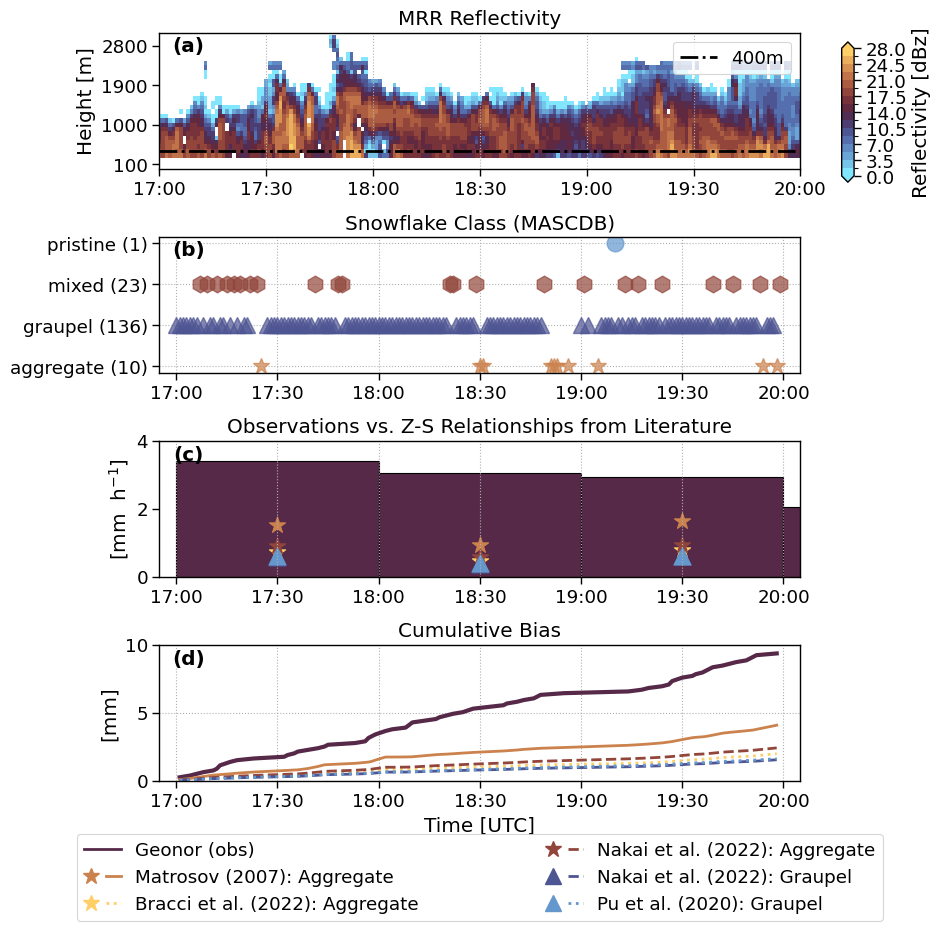

In [37]:
time_vals = fct.date2num(ds_day['time'].values)

# Define the region to highlight
x_start = xmin - pd.Timedelta(minutes=5)
x_end = xmax + pd.Timedelta(minutes=5)
y_start = 0.5 # slightly below the min y-value 
y_end = 30.5
x_width = x_end - x_start
y_height = y_end - y_start


fig, axsm = plt.subplots(4, 1, figsize=(8.27, 7.014/3*4), )#sharex=True, )
axs = axsm.flatten()

# a) 
fct.plot_pcolormesh_with_cbar(ax=axs[0], fig=fig, data=ds_day['Ze'].transpose('range','time'), x=time_vals, y=ds_day['range'], cmap=cmap, norm=norm, cbar_bounds=bounds[::2], cbar_label=f"Reflectivity [{ds_day['Ze'].attrs['units']}]", cbar_pos=[cbar_left, cbar_top -0 *cbar_step, cbar_width, cbar_height])
axs[0].hlines(4., ds_day.time.values[0], ds_day.time.values[-1], colors='k', linestyles='-.', label='400m')
axs[0].legend(loc='upper right')
axs[0].set_xlim([day_start, day_end])


# create a rectangle path
# rect = Rectangle((x_start, y_start), x_width, y_height, linewidth=2, edgecolor='k', linestyle='-', fill=False, )
# axs[0].add_patch(rect)

fct.format_range_axis(axs[0], ds_day)
# -----------

# b)
counts = []
for y_pos, (name, level) in enumerate(particle_classes, 1) :
    
    data = (df_day['snowflake_class_name'].where(df_day['snowflake_class_name'] == name)).dropna()
    counts.append(len(data))

    axs[1].plot(fct.date2num(data.index), 
                np.full(len(data.index), level),
                marker=markers[y_pos - 1], linestyle='None',
                color=fct.custom_colors[name], markersize=12, label=name, alpha=0.7)
    

axs[1].set_yticks(range(1,5))
axs[1].set_yticklabels([f"{name} ({cnt})" for (name, _), cnt in zip(particle_classes, counts)])
# -----------

# c)
dt = "event_offset"
for var, var_c in colors.items():
    # df_sec = df[dt].loc[slice(xmin, xmax + pd.Timedelta(hours=1))]
    df_sec = df_nearest[dt].loc[slice(xmin, xmax + pd.Timedelta(hours=1))]
    precip = df_sec[var].resample('1H', closed='left', label='left').sum()
    if var == 'Geonor':
        axs[2].bar(precip.index+pd.Timedelta(minutes=30), precip, width=np.timedelta64(60,'m'), align='center', color=var_c[0], edgecolor='k', label=var_c[1])
    else: 
        axs[2].scatter(precip.index+pd.Timedelta(minutes=30), precip, marker=var_c[3], color=var_c[0], s=150, edgecolor=var_c[0])
axs[2].set_ylabel("[mm  h$^{-1}$]")
axs[2].set_ylim([0, 4])
# axs[2].set_xlim([x_start, x_end])


# -----------

# d)
for var, var_c in colors.items():
    # df_sec = df[dt].loc[slice(xmin, xmax)]
    # precip = df_day[var].fillna(0).cumsum()
    df_sec = df_nearest[dt].loc[slice(xmin, xmax)]
    precip = df_sec[var].fillna(0).cumsum()
    if var == 'Geonor':
        linewidth = 3
    else:
        linewidth = 2
    axs[3].plot(precip.index, precip, color=var_c[0], label=var_c[1], linestyle=var_c[2], linewidth=linewidth)
axs[3].set_ylabel("[mm]")
axs[3].set_ylim([0, 10])
# axs[3].set_xlim([x_start, x_end])
# -----------

# pairing: either (marker,line) or (line,marker) depending on visual preference
legend_items = [
    geonor_line,
    (matro_mark, matro_line),
    (bracci_mark, bracci_line),
    (nakaiA_mark, nakaiA_line),
    (nakaiG_mark, nakaiG_line), 
    (Pu_mark, Pu_line)
]
bb = (fig.subplotpars.left -0.1, fig.subplotpars.bottom-0.15, 
fig.subplotpars.right-fig.subplotpars.left + 0.2,.1)

axs[3].legend(
    handles = legend_items,
    labels  = legend_labels,
    handler_map={tuple: HandlerTuple(ndivide=None)},
    bbox_to_anchor=bb, mode="expand", loc="lower left",
    ncol=2, borderaxespad=0., bbox_transform=fig.transFigure
)



date_form = DateFormatter("%H:%M")
for (i, ax), title in zip(enumerate(axs), ["MRR Reflectivity", "Snowflake Class (MASCDB)", "Observations vs. Z-S Relationships from Literature", "Cumulative Bias"]):
    ax.set(xlabel= "", title=title)
    ax.text(0.045, 0.9, fct.fig_label[i], fontweight='bold', horizontalalignment='center',verticalalignment='center', transform = ax.transAxes)
    ax.xaxis.grid(ls=':')
    if i == 1 or i == 3: 
        ax.yaxis.grid(ls=':')
    if i in [1, 2, 3]:
        ax.set_xlim([x_start, x_end])

    ax.tick_params(axis='x', labelrotation=0)
    plt.setp(ax.get_xticklabels(), horizontalalignment="center")
    ax.xaxis_date()
    ax.xaxis.set_major_formatter(date_form)
axs[-1].set(xlabel="Time [UTC]")
axs[-1].yaxis.grid(ls=':')

# fig.suptitle(f"{si te.split('.')[0]} ({ds_day.time.dt.date[0].values} — {ds_day.time.dt.date[-1].values})", fontweight="bold")
fig.subplots_adjust(top=0.91, hspace=0.5, )

# save image to png
plt.savefig(FIG_DIR + f'fig06.png', format='png', bbox_inches='tight', dpi=300, transparent=True,)

In [38]:
ds_day['Ze'].sel(time=slice('2023-03-08 17:00', '2023-03-08 20:00')).max().values.round(1)

np.float64(26.3)

In [39]:
ds_day['Ze'].sel(time=slice('2023-03-08 17:00', '2023-03-08 19:00'), range=3).mean('time').values.round(1)

np.float64(15.9)

In [40]:
dt

'event_offset'

In [41]:
df_nearest[dt].loc['2023-03-08']['Geonor'].sum().round(1)

np.float64(16.9)

In [42]:
df_nearest[dt].loc['2023-03-08']['air_temperature'].min().round(1), df_nearest[dt].loc['2023-03-08']['air_temperature'].max().round(1), 

(np.float64(-4.9), np.float64(-4.0))

In [43]:
df_sec = df_nearest[dt].loc[slice(xmin, xmax + pd.Timedelta(hours=1))]
_df_precip = df_sec[['Geonor', 'Matrosov_a_400', 'Bracci_a_400', 'Nakai_a_400', 'Nakai_g_400', 'Pu_g_400']]
_df_precip = _df_precip.resample('1H', closed='left', label='left').sum()
_df_precip

,Geonor,Matrosov_a_400,Bracci_a_400,Nakai_a_400,Nakai_g_400,Pu_g_400
time,,,,,,
2023-03-08 17:00:00,3.4011,1.512908,0.736537,0.890149,0.568043,0.593969
2023-03-08 18:00:00,3.0357,0.929663,0.456850,0.588669,0.375656,0.408481
2023-03-08 19:00:00,2.9204,1.638172,0.793914,0.933954,0.595997,0.615005
2023-03-08 20:00:00,2.0375,0.942212,0.464437,0.607593,0.387732,0.424368


In [44]:
_df_precip.round(1)

,Geonor,Matrosov_a_400,Bracci_a_400,Nakai_a_400,Nakai_g_400,Pu_g_400
time,,,,,,
2023-03-08 17:00:00,3.4,1.5,0.7,0.9,0.6,0.6
2023-03-08 18:00:00,3.0,0.9,0.5,0.6,0.4,0.4
2023-03-08 19:00:00,2.9,1.6,0.8,0.9,0.6,0.6
2023-03-08 20:00:00,2.0,0.9,0.5,0.6,0.4,0.4


In [45]:
_df_precip.iloc[:,1:].sub(_df_precip.iloc[:,0], axis=0).round(2)

,Matrosov_a_400,Bracci_a_400,Nakai_a_400,Nakai_g_400,Pu_g_400
time,,,,,
2023-03-08 17:00:00,-1.89,-2.66,-2.51,-2.83,-2.81
2023-03-08 18:00:00,-2.11,-2.58,-2.45,-2.66,-2.63
2023-03-08 19:00:00,-1.28,-2.13,-1.99,-2.32,-2.31
2023-03-08 20:00:00,-1.10,-1.57,-1.43,-1.65,-1.61


In [46]:
_df_precip.iloc[:,1:].sub(_df_precip.iloc[:,0], axis=0).mean(axis=0).round(2)

Matrosov_a_400   -1.59
Bracci_a_400     -2.24
Nakai_a_400      -2.09
Nakai_g_400      -2.37
Pu_g_400         -2.34
dtype: float64

In [47]:
df_sec = df_nearest[dt].loc[slice(xmin, xmax)]
precip = df_sec[['Geonor', 'Matrosov_a_400', 'Bracci_a_400', 'Nakai_a_400', 'Nakai_g_400', 'Pu_g_400']].fillna(0).cumsum()
precip.iloc[-1,:].round(1)


Geonor            9.4
Matrosov_a_400    4.1
Bracci_a_400      2.0
Nakai_a_400       2.4
Nakai_g_400       1.5
Pu_g_400          1.6
Name: 2023-03-08 19:58:00, dtype: float64

In [48]:
# precip.loc['2023-02-23 08:00'].round(1)

In [49]:
precip.iloc[:,1:].sub(precip.iloc[:,0], axis=0).round(2)

,Matrosov_a_400,Bracci_a_400,Nakai_a_400,Nakai_g_400,Pu_g_400
time,,,,,
2023-03-08 17:01:00,-0.17,-0.21,-0.19,-0.21,-0.21
2023-03-08 17:04:00,-0.22,-0.30,-0.28,-0.31,-0.31
2023-03-08 17:06:00,-0.27,-0.39,-0.36,-0.41,-0.41
2023-03-08 17:08:00,-0.32,-0.48,-0.45,-0.51,-0.51
2023-03-08 17:11:00,-0.34,-0.55,-0.52,-0.60,-0.60
2023-03-08 17:12:00,-0.45,-0.67,-0.63,-0.72,-0.71
2023-03-08 17:13:00,-0.68,-0.91,-0.87,-0.96,-0.96
2023-03-08 17:16:00,-0.87,-1.14,-1.08,-1.19,-1.18
2023-03-08 17:18:00,-0.96,-1.24,-1.18,-1.30,-1.29


### Seasonal overview
use minuetly data

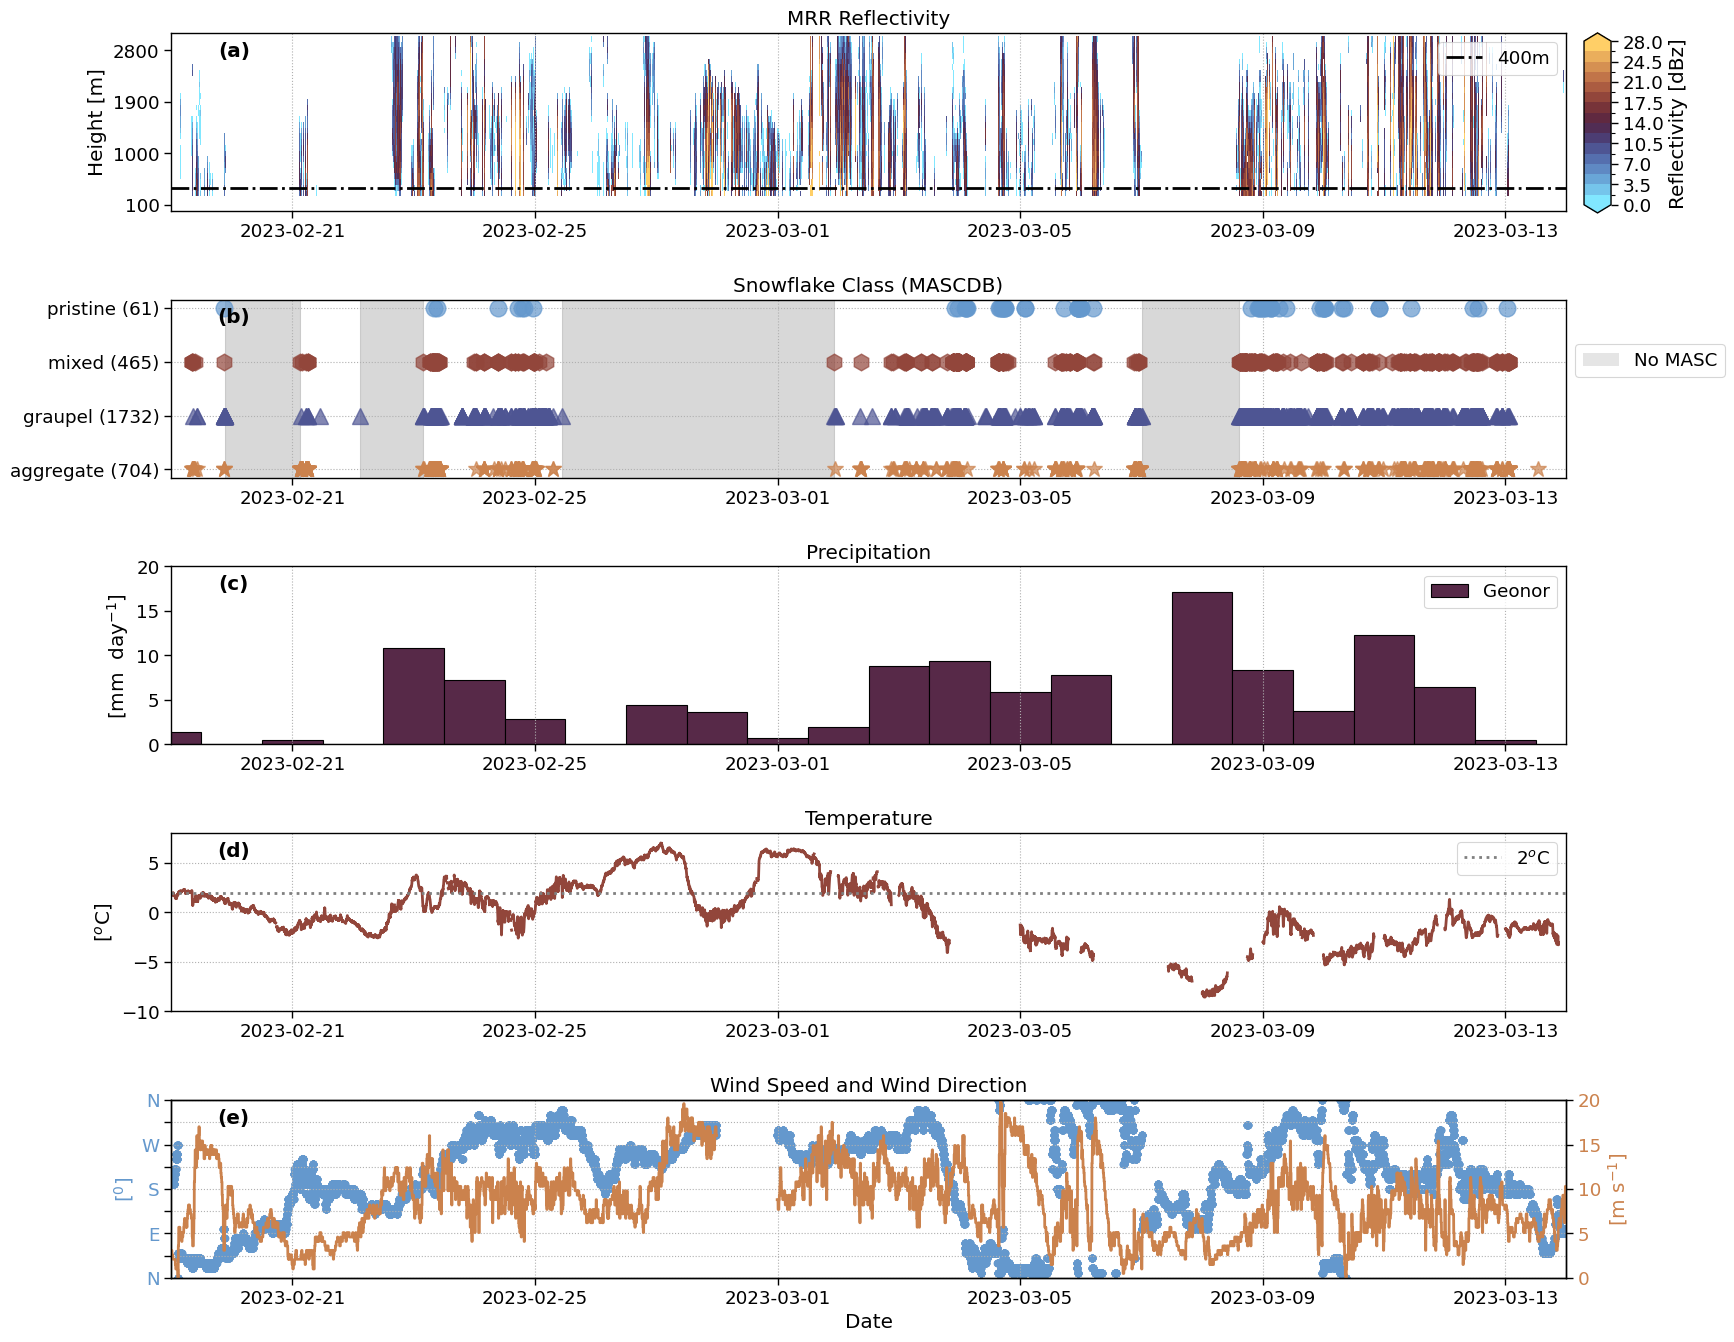

In [50]:
dt = '1min'
day_start = pd.Timestamp("2023-02-19 00:00:00")
day_end = pd.Timestamp("2023-03-13 23:59:00")

ds_season = ds_23.sel(time=slice(day_start, day_end))
df_season = df[dt].loc[slice(day_start, day_end)]
df_season_no_sf_class = df_no_sf_class[dt].loc[slice(day_start, day_end)]

# get the “no MASC available” timestamps
all_times = df_season_no_sf_class.index
masc_times = df_season.index

# Example threshold
threshold = pd.Timedelta('1440min')

# Step 1: sort (just to be safe)
masc_times = masc_times.sort_values()
# Step 2: compute the gaps between consecutive MASC timestamps
deltat = masc_times.to_series().diff()
# Step 3: find where the gap exceeds threshold
gap_starts = masc_times[deltat > threshold]          # first timestamp *after* a long gap
gap_ends = gap_starts - deltat[deltat > threshold]       # last timestamp *before* the gap

gaps = list(zip(gap_ends, gap_starts))

time_vals = fct.date2num(ds_season['time'].values)

# Define the region to highlight
x_start = xmin - pd.Timedelta(minutes=5)
x_end = xmax + pd.Timedelta(minutes=5)
y_start = 0.5 # slightly below the min y-value 
y_end = 30.5
x_width = x_end - x_start
y_height = y_end - y_start


fig, axsm = plt.subplots(5, 1, figsize=(18, 15), )#sharex=True, )
axs = axsm.flatten()

# a) 
fct.plot_pcolormesh_with_cbar(ax=axs[0], fig=fig, data=ds_season['Ze'].transpose('range','time'), x=time_vals, y=ds_season['range'], cmap=cmap, norm=norm, cbar_bounds=bounds[::2], cbar_label=f"Reflectivity [{ds_season['Ze'].attrs['units']}]", cbar_pos=[cbar_left-0.04, 0.82, cbar_width, cbar_height/5*4])
axs[0].hlines(4., ds_season.time.values[0], ds_season.time.values[-1], colors='k', linestyles='-.', label='400m')
axs[0].legend(loc='upper right')


# # create a rectangle path
# rect = Rectangle((x_start, y_start), x_width, y_height, linewidth=2, edgecolor='k', linestyle='-', fill=False, )
# axs[0].add_patch(rect)

fct.format_range_axis(axs[0], ds_season)
# -----------

# b)
counts = []
for y_pos, (name, level) in enumerate(particle_classes, 1) :
    
    data = (df_season['snowflake_class_name'].where(df_season['snowflake_class_name'] == name)).dropna()
    counts.append(len(data))

    axs[1].plot(fct.date2num(data.index), 
                np.full(len(data.index), level),
                marker=markers[y_pos - 1], linestyle='None',
                color=fct.custom_colors[name], markersize=12, label=name, alpha=0.7)

for g_start, g_end in gaps:
    axs[1].axvspan(g_start, g_end, color='grey', alpha=0.3)    

axs[1].legend(handles=[
    Patch(facecolor='grey', alpha=0.2, label="No MASC"),
], bbox_to_anchor=(1.0, 0.8))
axs[1].set_yticks(range(1,5))
axs[1].set_yticklabels([f"{name} ({cnt})" for (name, _), cnt in zip(particle_classes, counts)])
# -----------

# c)
precip = df_season_no_sf_class['Geonor'].resample('24H').sum()
# precip = ds_season['Geonor'].resample(time='24H').sum()
axs[2].bar(precip.index, precip, width=np.timedelta64(60*24,'m'), align='center', color=colors['Geonor'][0], edgecolor='k', label='Geonor')
 
axs[2].set_ylabel("[mm  day$^{-1}$]")
axs[2].legend()
axs[2].set_ylim([0, 20])
# -----------

# d)
temp = ds_season['air_temperature']
axs[3].plot(temp.time.values, temp, color=fct.custom_colors['mixed'])
axs[3].hlines(2., temp.time.values[0], temp.time.values[-1], colors='grey', linestyles=':', label='$2^{o}$C')
axs[3].set_ylabel("[$^{o}$C]")
axs[3].set_ylim([-10, 8])
axs[3].legend()
# -----------

# e)
wd = ds_season['wind_direction']
axs[4].scatter(wd.time.values, wd, color=fct.custom_colors['pristine'])
axs[4].set_ylabel('[$^{0}$]', color=fct.custom_colors['pristine'])
axs[4].tick_params(axis='y', labelcolor=fct.custom_colors['pristine'])
axs[4].set_ylim(0,360)
axs[4].set_yticks(np.arange(0,365,45))
axs[4].set_yticklabels(['N', '', 'E', '' , 'S', '', 'W', '', 'N'])

ws = ds_season['wind_speed']
ax2 = axs[4].twinx()
ax2.plot(ws.time.values, ws, color=fct.custom_colors['aggregate'])
ax2.set_ylabel('[m s$^{-1}$]', color=fct.custom_colors['aggregate'])
ax2.tick_params(axis='y', labelcolor=fct.custom_colors['aggregate'])
ax2.set_ylim(0,20)




date_form = DateFormatter("%Y-%m-%d")
for (i, ax), title in zip(enumerate(axs), ["MRR Reflectivity", "Snowflake Class (MASCDB)", "Precipitation", "Temperature", "Wind Speed and Wind Direction"]):
    ax.set(xlabel= "", title=title)
    ax.text(0.045, 0.9, fct.fig_label[i], fontweight='bold', horizontalalignment='center',verticalalignment='center', transform = ax.transAxes)
    ax.xaxis.grid(ls=':')
    if i == 1 or i == 3 or i == 4:
        ax.yaxis.grid(ls=':')
    ax.tick_params(axis='x', labelrotation=0)
    plt.setp(ax.get_xticklabels(), horizontalalignment="center")
    ax.xaxis_date()
    ax.xaxis.set_major_formatter(date_form)
    ax.set_xlim([day_start, day_end])


axs[-1].set(xlabel="Date")
axs[4].yaxis.grid(ls=':')

# fig.suptitle(f"{site.split('.')[0]} ({ds_season.time.dt.date[0].values} — {ds_season.time.dt.date[-1].values})", fontweight="bold")
fig.subplots_adjust(top=0.94, hspace=0.5, )

# save image to png
plt.savefig(FIG_DIR + 'fig03.png', format='png', bbox_inches='tight', dpi=300, transparent=True,)

In [51]:
directions_deg = df_season_no_sf_class['wind_direction']
def mean_wind_direction(directions_deg):
    # Convert degrees → radians
    directions_rad = np.deg2rad(directions_deg)

    # Compute mean of unit circle components
    sin_mean = np.mean(np.sin(directions_rad))
    cos_mean = np.mean(np.cos(directions_rad))

    # Compute the circular mean
    mean_rad = np.arctan2(sin_mean, cos_mean)

    # Convert radians → degrees
    mean_deg = np.rad2deg(mean_rad)

    # Ensure result is in [0, 360)
    print((mean_deg % 360).round(0))

mean_wind_direction(directions_deg)

215.0


In [52]:
gaps

[(Timestamp('2023-02-19 21:30:00'), Timestamp('2023-02-21 02:57:00')),
 (Timestamp('2023-02-22 02:55:00'), Timestamp('2023-02-23 03:33:00')),
 (Timestamp('2023-02-25 10:46:00'), Timestamp('2023-03-01 22:25:00')),
 (Timestamp('2023-03-07 00:05:00'), Timestamp('2023-03-08 14:40:00'))]

### Particle Type Frequency per Wind direction
use event-based data

In [53]:
dt = 'event_offset'
day_start = pd.Timestamp("2023-02-19 00:00:00")
day_end = pd.Timestamp("2023-03-13 23:59:00")

ds_season = ds_23.sel(time=slice(day_start, day_end))
df_season = df[dt].loc[slice(day_start, day_end)]
df_season_nearest = df_nearest[dt].loc[slice(day_start, day_end)]
df_season_no_sf_class = df_no_sf_class[dt].loc[slice(day_start, day_end)]


In [54]:
def wind_sector(deg):
    if (deg >= 337.5) or (deg < 22.5):
        return 'N'
    elif 22.5 <= deg < 67.5:
        return 'NE'
    elif 67.5 <= deg < 112.5:
        return 'E'
    elif 112.5 <= deg < 157.5:
        return 'SE'
    elif 157.5 <= deg < 202.5:
        return 'S'
    elif 202.5 <= deg < 247.5:
        return 'SW'
    elif 247.5 <= deg < 292.5:
        return 'W'
    else:
        return 'NW'

direction_labels = ['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW', ]

In [55]:
num_bins = len(direction_labels)
bin_width_deg = 360/num_bins
half_bin = bin_width_deg/2
# bin_edges = np.linspace(-half_bin, 360-half_bin, num_bins+1)
# bin_edges

In [56]:
# convert wind into [0, 360)
df_season['wind_direction'] = df_season['wind_direction'] % 360

# shift directions by half-bin, this makes North centered at 0
wd_shifted = (df_season['wind_direction'] + half_bin) % 360

# cut using clean bins
bin_edges = np.linspace(0, 360, num_bins +1)
bin_edges

array([  0.,  45.,  90., 135., 180., 225., 270., 315., 360.])

In [57]:
df_season['wind_direction_sector'] = pd.cut(df_season['wind_direction'], bins=bin_edges, labels=direction_labels, include_lowest=True)


In [58]:
#Group counts Compute Snowflake Frequencies per ( Wind Sector)
counts = df_season.groupby(['snowflake_class_name', 'wind_direction_sector']).size().reset_index(name='count')

# Pivot to a contingency table: rows=(temp, wind), columns=snowflake_class
pivot = counts.pivot_table(index=['wind_direction_sector'], columns='snowflake_class_name', values='count', fill_value=0)
# total row before normalization
pivot_with_total = pivot.copy()
pivot_with_total.loc['Total'] = pivot.sum(axis=0)



In [59]:
# normalize by wind sector and transpose for plotting
pivot_plot_sector = pivot_with_total.div(pivot_with_total.sum(axis=1), axis=0).T * 100
default_label = "% Frequency"
format = ".2f"
n_bins = 10
bounds = np.linspace(0, 100, n_bins +1)
cmap_base = cm.managua_r

cmaplist = [cmap_base(i/(n_bins -1)) for i in range(n_bins)]
custom_cmap = ListedColormap(cmaplist)
    
norm = BoundaryNorm(bounds, ncolors=custom_cmap.N)

In [60]:
print(dt)

event_offset


In [61]:
pivot

snowflake_class_name,aggregate,graupel,mixed,pristine
wind_direction_sector,,,,
N,7.0,51.0,10.0,1.0
NE,0.0,14.0,8.0,2.0
E,1.0,2.0,3.0,0.0
SE,24.0,28.0,33.0,0.0
S,22.0,149.0,28.0,0.0
SW,21.0,71.0,14.0,0.0
W,8.0,65.0,18.0,0.0
NW,4.0,17.0,6.0,0.0


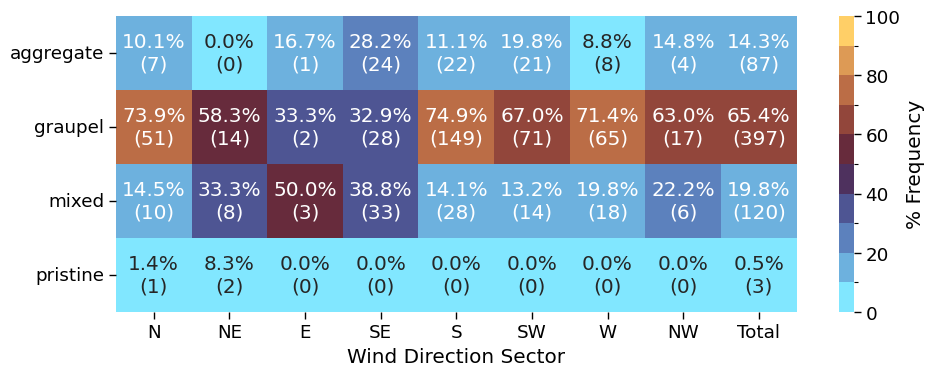

In [62]:
# Plot 
plt.figure(figsize=(10, 4))
annot_data_sector = pivot_plot_sector.round(1).astype(str) + "%\n(" + pivot_with_total.T.astype(int).astype(str) + ")"

ax = sns.heatmap(pivot_plot_sector, annot=annot_data_sector, fmt="", cmap=custom_cmap, norm=norm, cbar_kws={'label': default_label})

# Labeling
ax.set_xlabel("Wind Direction Sector")
ax.set_ylabel("")
plt.tight_layout()

# save image to png
plt.savefig(FIG_DIR + "fig04a.png", format='png', bbox_inches='tight', transparent=True,dpi=300)
# Frequencies are normalized by wind sector, highlighting the relative distribution of snowflake habits for a given flow direction. 

In [63]:
pivot_plot_sector

wind_direction_sector,N,NE,E,SE,S,SW,W,NW,Total
snowflake_class_name,,,,,,,,,
aggregate,10.144928,0.000000,16.666667,28.235294,11.055276,19.811321,8.791209,14.814815,14.332784
graupel,73.913043,58.333333,33.333333,32.941176,74.874372,66.981132,71.428571,62.962963,65.403624
mixed,14.492754,33.333333,50.000000,38.823529,14.070352,13.207547,19.780220,22.222222,19.769357
pristine,1.449275,8.333333,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.494234


#### Normalize by habit class instead of wind sector
Given this habit, which wind direcitons did it occur?

In [64]:
pivot_plot_habit = pivot.div(pivot.sum(axis=0), axis=1)*100
# transpose for plotting consistency
pivot_plot_habit = pivot_plot_habit.T
# annotation for habit-normalized plot
annot_data_habit = (pivot_plot_habit.round(1).astype(str) +"%\n(" + 
                    pivot.T.astype(int).astype(str) + ")")

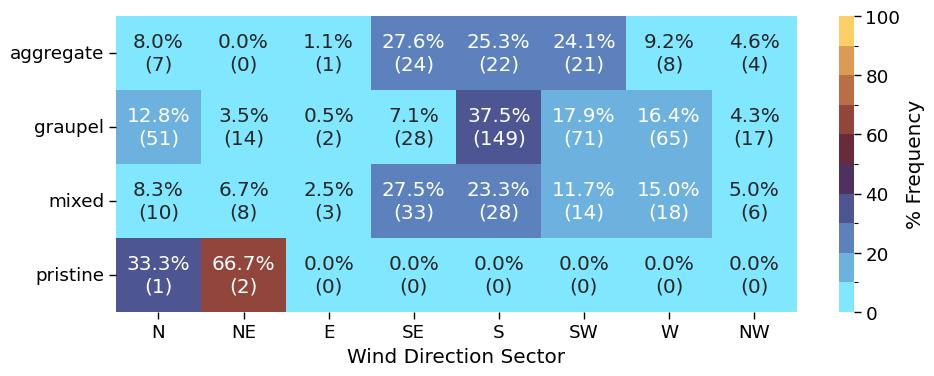

In [65]:
# Plot 
plt.figure(figsize=(10, 4))

ax = sns.heatmap(pivot_plot_habit, annot=annot_data_habit, fmt="", cmap=custom_cmap, norm=norm, cbar_kws={'label': default_label})

# Labeling
ax.set_xlabel("Wind Direction Sector")
ax.set_ylabel("")
plt.tight_layout()

# save image to png
plt.savefig(FIG_DIR + "fig04b.png", format='png', bbox_inches='tight', transparent=True,dpi=300)
# Frequencies are normalized by snowflake habit, highlighting preferred wind directions for each habit class

### CFAD per particle type
use event-based data

In [66]:
print(dt)

event_offset


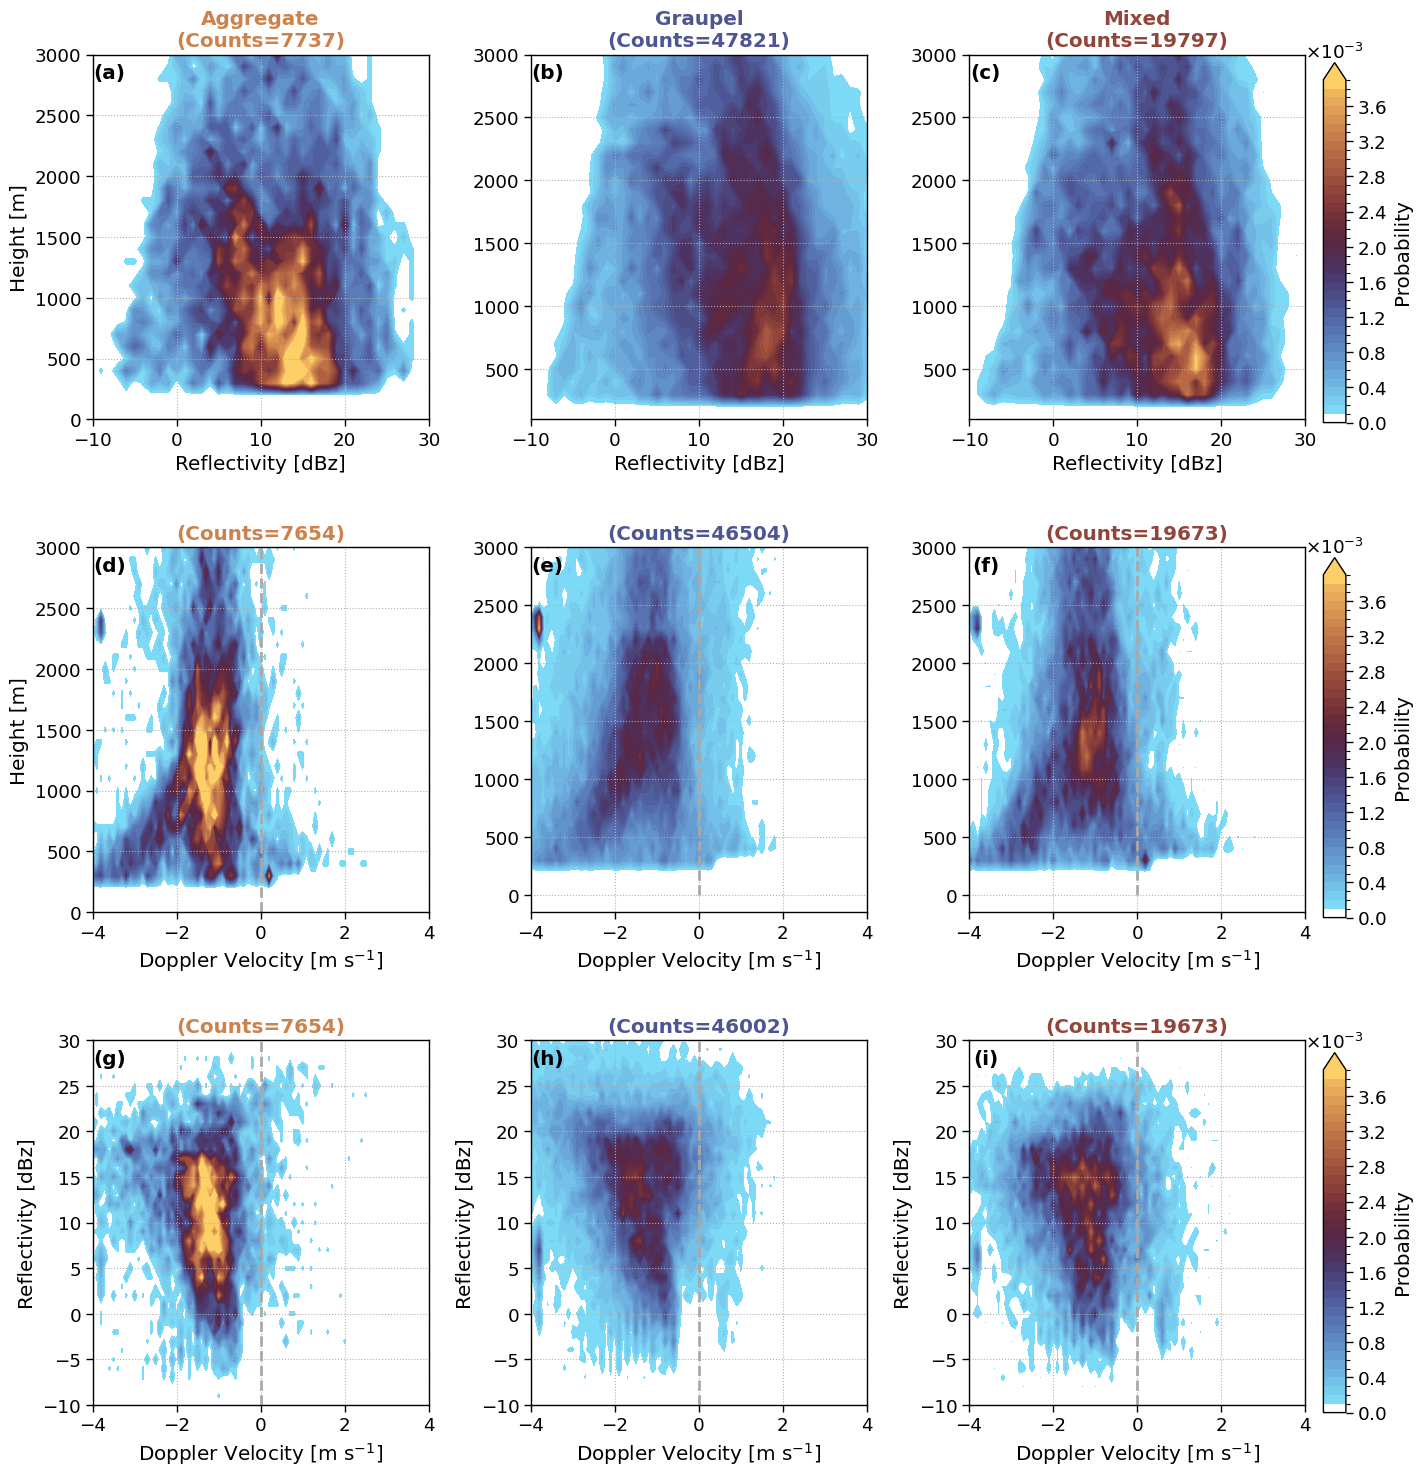

In [67]:
H_ze = dict()
H_ze_prob = dict()

H_w = dict()
H_w_prob = dict()

H_ze_w = dict()
H_ze_w_prob = dict()

for sf_class, df_class in sf_class_dict[dt].items():
    
    _ds_in_dt = fct.get_ds_in_precip_event(sf_class_dict[dt][sf_class], ds_season)
    H_ze[sf_class], H_ze_prob[sf_class] = fct.probability_distribution(_ds_in_dt, 'Ze', 'height',np.arange(-10.5, 31, 1), np.arange(50, 3150, 100))# fct.ze_bins, fct.height_bins)

    H_w[sf_class], H_w_prob[sf_class] = fct.probability_distribution(_ds_in_dt, 'W', 'height', np.arange(-4.05, 4.1, 0.1), np.arange(50, 3150, 100))#fct.W_bins, fct.height_bins)

    H_ze_w[sf_class], H_ze_w_prob[sf_class] = fct.probability_distribution(_ds_in_dt, 'W', 'Ze', np.arange(-4.05, 4.1, 0.1), np.arange(-10.5, 31, 1))

fct.plt_prob_agg_graupel_mixed(H_ze_prob, H_ze, H_w_prob, H_w, H_ze_w_prob, H_ze_w)
# save image to png
plt.savefig(FIG_DIR + "figA1.png", format='png', bbox_inches='tight', transparent=True,dpi=300)

In [68]:
len(np.arange(-10.5, 31, 1)), len(np.arange(50, 3150, 100))

(42, 31)

In [69]:
np.arange(50, 3150, 100)[:21]

array([  50,  150,  250,  350,  450,  550,  650,  750,  850,  950, 1050,
       1150, 1250, 1350, 1450, 1550, 1650, 1750, 1850, 1950, 2050])

In [70]:
H_ze_prob['aggregate'][:21,:].min(),H_ze_prob['aggregate'][:21,:].max(),

(np.float64(0.0), np.float64(0.004523717203050278))

### Geonor vs. Literature precipitation scatter
use event-based data

In [71]:
print(dt)

event_offset


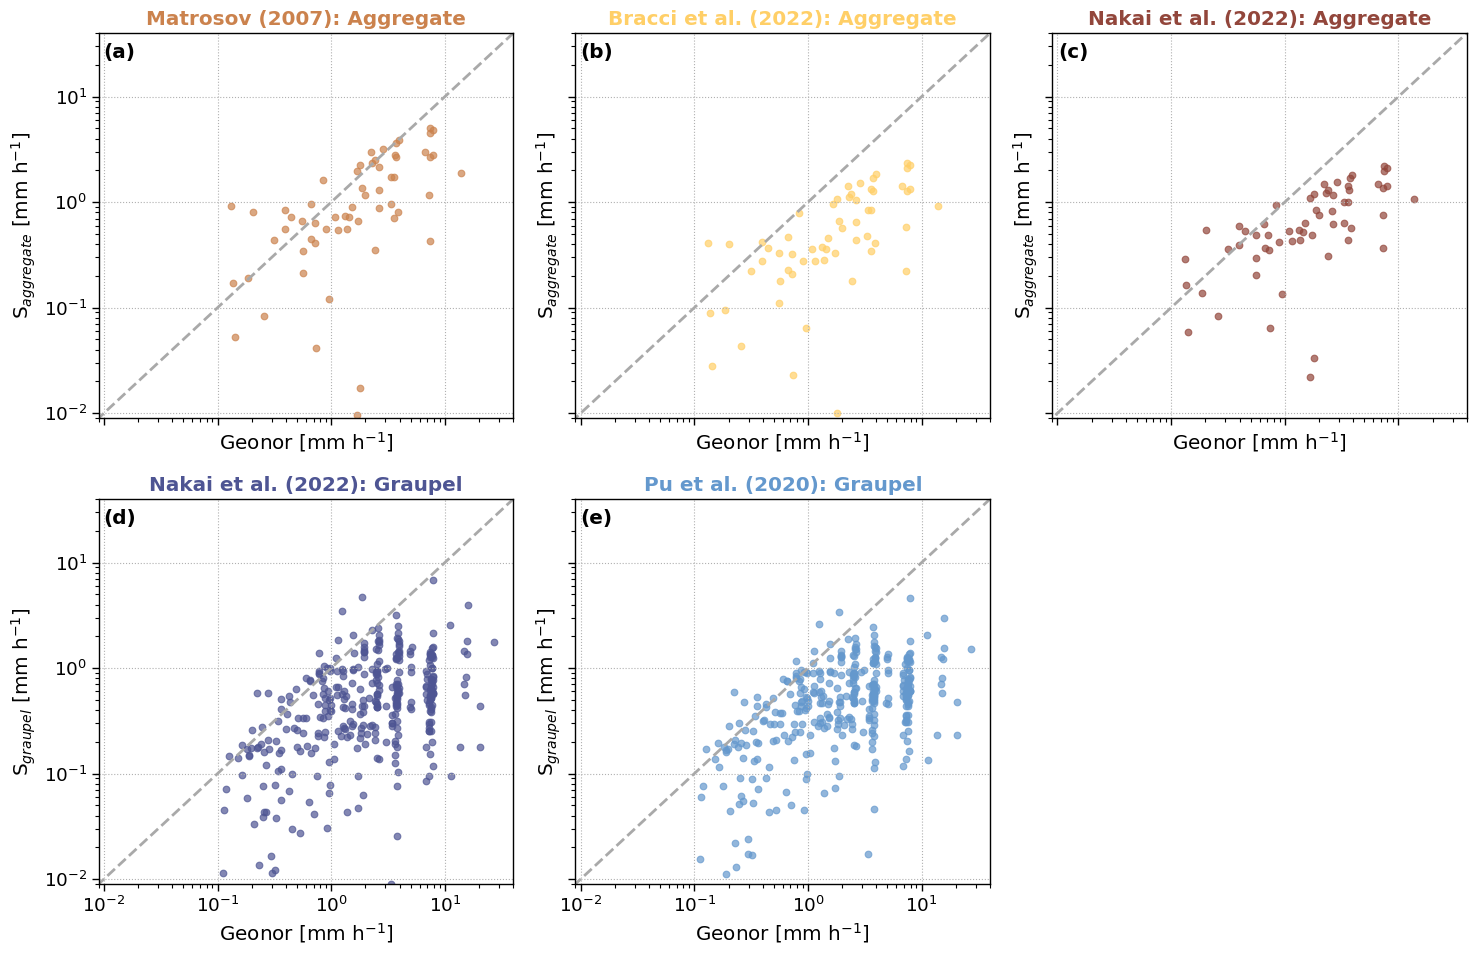

In [72]:
fct.plt_precip_scatter_literature(sf_class_dict[dt], title="")
# save image to png
plt.savefig(FIG_DIR + f"precip_vs_literature_precip_1min_{site}_20230219_20230313.png", format='png', bbox_inches='tight', transparent=True,dpi=300)


### Cumulation season
Use the event-based data and the "nearest" crystal class data

In [73]:
print(dt)

event_offset


In [74]:
# Combine where MASC observes aggregate --> apply Z-S for aggregates, 
# where MASC observes graupel --> apply Z-S for graupel 
# For the combined Z-S relationship, use the "nearest" observe snowflake type (done in different notebook).
# For the "mixed" category, do the calculation twice, once where I assume mixed=graupel and another time where mixed=aggregate

# mixed = aggregate
mixed_aggregate=pd.DataFrame()
mixed_aggregate['Geonor_aggregate_graupel_only'] = pd.concat([aggregate_nearest[dt]['Geonor'], mixed_nearest[dt]['Geonor'], graupel_nearest[dt]['Geonor']]).sort_index()
mixed_aggregate['Matrosov_Nakai'] = pd.concat([aggregate_nearest[dt]['Matrosov_a_400'], mixed_nearest[dt]['Matrosov_a_400'], graupel_nearest[dt]['Nakai_g_400']]).sort_index()
mixed_aggregate['Bracci_Nakai'] = pd.concat([aggregate_nearest[dt]['Bracci_a_400'], mixed_nearest[dt]['Bracci_a_400'], graupel_nearest[dt]['Nakai_g_400']]).sort_index()
mixed_aggregate['Nakai_Nakai'] = pd.concat([aggregate_nearest[dt]['Nakai_a_400'], mixed_nearest[dt]['Nakai_a_400'], graupel_nearest[dt]['Nakai_g_400']]).sort_index()

mixed_aggregate['Matrosov_Pu'] = pd.concat([aggregate_nearest[dt]['Matrosov_a_400'], mixed_nearest[dt]['Matrosov_a_400'], graupel_nearest[dt]['Pu_g_400']]).sort_index()
mixed_aggregate['Bracci_Pu'] = pd.concat([aggregate_nearest[dt]['Bracci_a_400'], mixed_nearest[dt]['Bracci_a_400'], graupel_nearest[dt]['Pu_g_400']]).sort_index()
mixed_aggregate['Nakai_Pu'] = pd.concat([aggregate_nearest[dt]['Nakai_a_400'], mixed_nearest[dt]['Nakai_a_400'], graupel_nearest[dt]['Pu_g_400']]).sort_index()

# mixed = graupel
mixed_graupel=pd.DataFrame()
mixed_graupel['Geonor_aggregate_graupel_only'] = pd.concat([aggregate_nearest[dt]['Geonor'], mixed_nearest[dt]['Geonor'], graupel_nearest[dt]['Geonor']]).sort_index()
mixed_graupel['Matrosov_Nakai'] = pd.concat([aggregate_nearest[dt]['Matrosov_a_400'], mixed_nearest[dt]['Nakai_g_400'], graupel_nearest[dt]['Nakai_g_400']]).sort_index()
mixed_graupel['Bracci_Nakai'] = pd.concat([aggregate_nearest[dt]['Bracci_a_400'], mixed_nearest[dt]['Nakai_g_400'], graupel_nearest[dt]['Nakai_g_400']]).sort_index()
mixed_graupel['Nakai_Nakai'] = pd.concat([aggregate_nearest[dt]['Nakai_a_400'], mixed_nearest[dt]['Nakai_g_400'], graupel_nearest[dt]['Nakai_g_400']]).sort_index()

mixed_graupel['Matrosov_Pu'] = pd.concat([aggregate_nearest[dt]['Matrosov_a_400'], mixed_nearest[dt]['Pu_g_400'], graupel_nearest[dt]['Pu_g_400']]).sort_index()
mixed_graupel['Bracci_Pu'] = pd.concat([aggregate_nearest[dt]['Bracci_a_400'], mixed_nearest[dt]['Pu_g_400'], graupel_nearest[dt]['Pu_g_400']]).sort_index()
mixed_graupel['Nakai_Pu'] = pd.concat([aggregate_nearest[dt]['Nakai_a_400'], mixed_nearest[dt]['Pu_g_400'], graupel_nearest[dt]['Pu_g_400']]).sort_index()

/tmp/ipykernel_4086416/4092374415.py:91: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


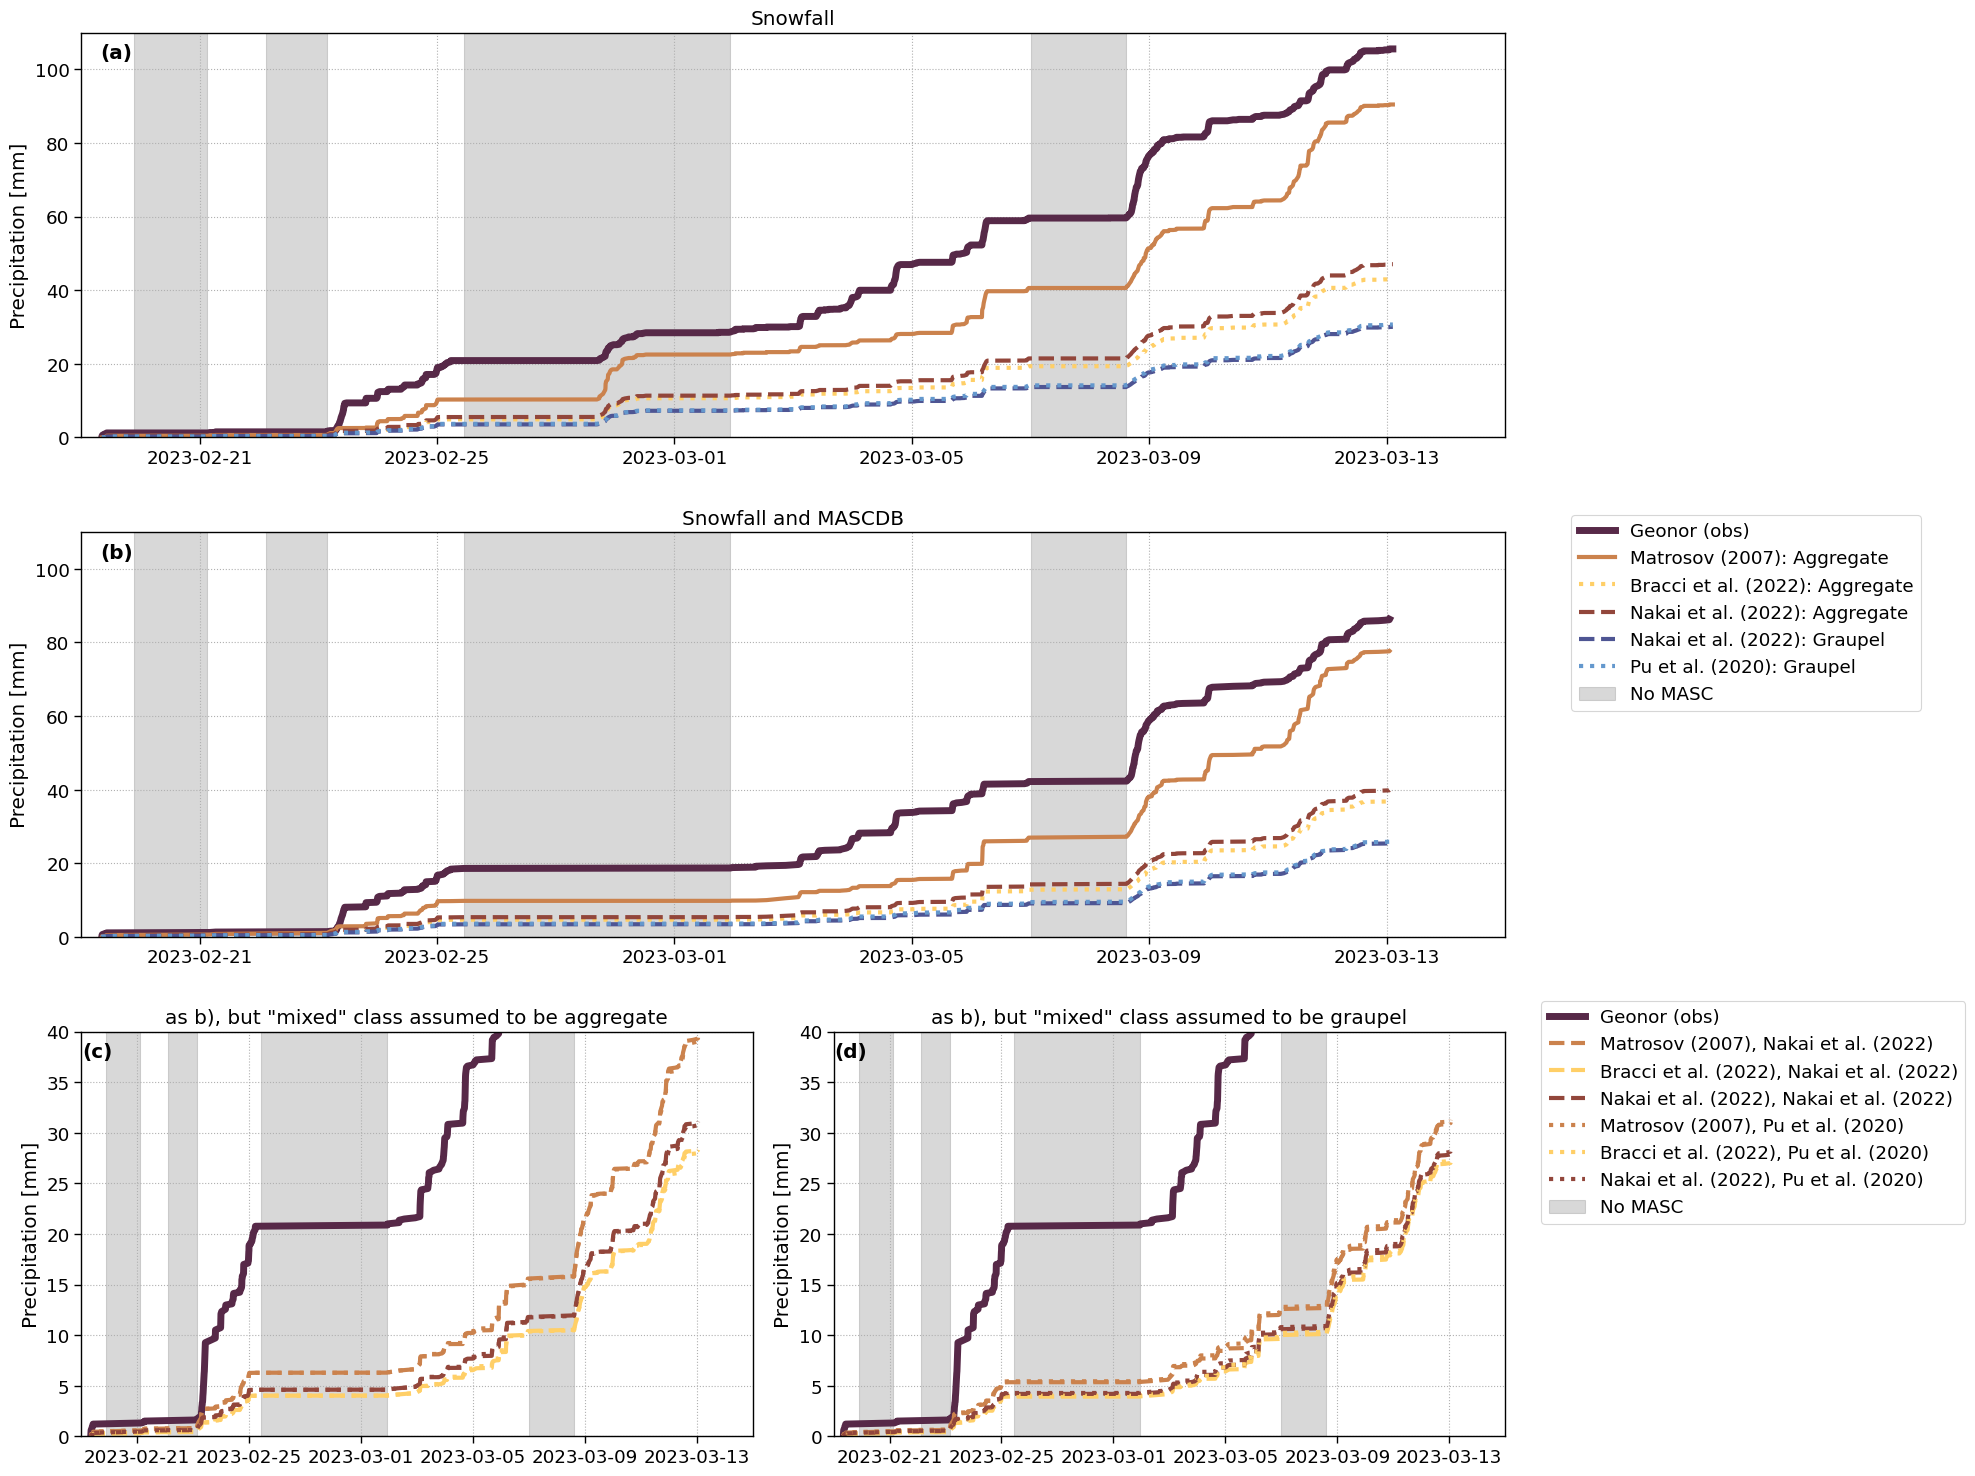

In [75]:
fig, axd = plt.subplot_mosaic([['first', 'first'],
                               ['second', 'second'],
                               ['left', 'right'],
                               ],
                              constrained_layout=True, figsize=(20,15), )#sharex=True)

# a)
for var, var_c in colors.items():
    if var == 'Geonor':
        linewidth = 5
    else: 
        linewidth = 3
    # precip2 = ds_season[var].cumsum()
    # axd['first'].plot(precip2.time.values, precip2, color=var_c[0], label= var_c[1], linewidth=linewidth, linestyle=var_c[2])
    precip = df_season_no_sf_class[var].cumsum()
    precip = precip.fillna(method='ffill')
    axd['first'].plot(precip.index, precip, color=var_c[0], label= var_c[1], linewidth=linewidth, linestyle=var_c[2])
axd['first'].set_ylim([0, 110])
# -----------

# b)
for var, var_c in colors.items():
    if var == 'Geonor':
        linewidth = 5
    else: 
        linewidth = 3
    precip = df_season[var].cumsum(skipna=True)
    precip = precip.fillna(method='ffill')
    axd['second'].plot(precip.index, precip, color=var_c[0], label= var_c[1], linewidth=linewidth, linestyle=var_c[2])
    # for t in no_masc_times:
    #     axd['left'].axvline(t, color="red", alpha=0.15, linewidth=6)
    # Shade gaps

axd['second'].set_ylim([0, 110])
# -----------

# c) and d)
for var, var_c in colors2.items():
    if var == 'Geonor_aggregate_graupel_only':
        linewidth = 5
    else:
        linewidth = 3
    precip = mixed_aggregate[var].cumsum(skipna=True)
    precip = precip.fillna(method='ffill')
    axd['left'].plot(precip.index, precip, color=var_c[0], label= var_c[1], linewidth=linewidth, linestyle=var_c[2],)
    

    precip2 = mixed_graupel[var].cumsum(skipna=True)
    precip2 = precip2.fillna(method='ffill')
    axd['right'].plot(precip2.index, precip2, color=var_c[0], label= var_c[1], linewidth=linewidth, linestyle=var_c[2],)

axd['left'].set_ylim([0, 40])
axd['right'].set_ylim([0, 40])

# -----------




date_form = DateFormatter("%Y-%m-%d")
first = True
for (i, key), title in zip(enumerate(axd), ['Snowfall', 'Snowfall and MASCDB', 'as b), but "mixed" class assumed to be aggregate', 'as b), but "mixed" class assumed to be graupel']):
    axd[key].set(xlabel= "", title=title)
    axd[key].text(0.025, 0.95, fct.fig_label[i], fontweight='bold', horizontalalignment='center',verticalalignment='center', transform = axd[key].transAxes)
    axd[key].xaxis.grid(which='both', ls=':')
    axd[key].yaxis.grid(which='both', ls=':')
    axd[key].tick_params(axis='x', labelrotation=0)
    plt.setp(axd[key].get_xticklabels(), horizontalalignment='center')
    axd[key].xaxis_date()
    axd[key].xaxis.set_major_formatter(date_form)
    axd[key].set_xlim([pd.Timestamp("'2023-02-19' 00:00:00"), pd.Timestamp(f"'2023-03-15' 00:00:00")])
    axd[key].set_ylabel("Precipitation [mm]")
    first = True
    for g_start, g_end in gaps:
        if first:
            axd[key].axvspan(g_start, g_end, color='grey', alpha=0.3, label='No MASC')
            first = False
        else:
            axd[key].axvspan(g_start, g_end, color='grey', alpha=0.3, label='_nolegend_')



axd['second'].legend(loc='center left', bbox_to_anchor=(1.04, 0.8))
axd['right'].legend(loc='center left', bbox_to_anchor=(1.04, 0.8))
# axd['right'].legend(loc='center left', bbox_to_anchor=(1, 0.5))
# axd['second'].legend(handles=[
#     Patch(facecolor='red', alpha=0.2, label="No MASC observation"),
# ])


plt.tight_layout()
# save image to png
plt.savefig(FIG_DIR + f'cumsum_precip_{site}_20230219_20230313.png', format='png', bbox_inches='tight', dpi=300, transparent=True,)

In [76]:
precip = df_season[['Geonor', 'Matrosov_a_400', 'Bracci_a_400', 'Nakai_a_400', 'Nakai_g_400', 'Pu_g_400']].cumsum(skipna=True)
precip.round(1)

,Geonor,Matrosov_a_400,Bracci_a_400,Nakai_a_400,Nakai_g_400,Pu_g_400
time,,,,,,
2023-02-19 08:27:00,0.1,0.1,0.0,0.0,0.0,0.0
2023-02-19 08:29:00,0.3,0.2,0.1,0.1,0.1,0.1
2023-02-19 08:33:00,0.6,0.2,0.1,0.1,0.1,0.1
2023-02-19 08:40:00,0.7,0.3,0.1,0.2,0.1,0.1
2023-02-19 09:24:00,0.8,0.3,0.1,0.2,0.1,0.1
...,...,...,...,...,...,...
2023-03-12 14:51:00,85.8,77.4,36.7,39.6,25.3,25.7
2023-03-12 20:43:00,85.9,77.5,36.7,39.7,25.3,25.8
2023-03-12 23:17:00,86.0,77.5,36.8,39.8,25.4,25.8


In [77]:
precip.iloc[:,1:].sub(precip.iloc[:,0], axis=0)#.mean(axis=0).round(2)

,Matrosov_a_400,Bracci_a_400,Nakai_a_400,Nakai_g_400,Pu_g_400
time,,,,,
2023-02-19 08:27:00,-0.038623,-0.075793,-0.068649,-0.083974,-0.082792
2023-02-19 08:29:00,-0.160884,-0.250364,-0.241195,-0.274451,-0.274568
2023-02-19 08:33:00,-0.319152,-0.440945,-0.421072,-0.469680,-0.467062
2023-02-19 08:40:00,-0.416208,-0.544606,-0.516556,-0.570851,-0.564269
2023-02-19 09:24:00,-0.527036,-0.655585,-0.626865,-0.681482,-0.674356
...,...,...,...,...,...
2023-03-12 14:51:00,-8.420525,-49.077582,-46.139860,-60.484378,-60.065099
2023-03-12 20:43:00,-8.461760,-49.164585,-46.209221,-60.576622,-60.152692
2023-03-12 23:17:00,-8.523352,-49.260055,-46.274516,-60.666163,-60.229337


In [78]:
precip.iloc[:,1:].sub(precip.iloc[:,0], axis=0).abs().idxmax()#.max()

Matrosov_a_400   2023-03-08 20:55:00
Bracci_a_400     2023-03-13 01:13:00
Nakai_a_400      2023-03-13 01:13:00
Nakai_g_400      2023-03-13 01:13:00
Pu_g_400         2023-03-13 01:13:00
dtype: datetime64[ns]

In [79]:
precip.iloc[:,1:].sub(precip.iloc[:,0], axis=0).loc['2023-03-08 20:00':'2023-03-08 21:00'].round(1)

,Matrosov_a_400,Bracci_a_400,Nakai_a_400,Nakai_g_400,Pu_g_400
time,,,,,
2023-03-08 20:03:00,-20.7,-37.9,-35.7,-42.2,-41.7
2023-03-08 20:04:00,-20.7,-38.0,-35.8,-42.3,-41.8
2023-03-08 20:06:00,-20.9,-38.1,-35.9,-42.4,-41.9
2023-03-08 20:13:00,-21.0,-38.4,-36.1,-42.7,-42.1
2023-03-08 20:17:00,-21.1,-38.5,-36.2,-42.8,-42.2
2023-03-08 20:18:00,-21.3,-38.6,-36.3,-42.9,-42.3
2023-03-08 20:23:00,-21.5,-38.8,-36.5,-43.1,-42.6
2023-03-08 20:25:00,-21.6,-39.0,-36.7,-43.3,-42.7
2023-03-08 20:40:00,-21.5,-39.0,-36.7,-43.3,-42.7


In [80]:
dt = '1min'
snowflake_class_count = pd.concat([aggregate[dt]['snowflake_class_name'].groupby(aggregate[dt].index.date).count().rename('aggregate_count'), 
                                   graupel[dt]['snowflake_class_name'].groupby(graupel[dt].index.date).count().rename('graupel_count'),
                                   mixed[dt]['snowflake_class_name'].groupby(mixed[dt].index.date).count().rename('mixed_count'),
                                   pristine[dt]['snowflake_class_name'].groupby(pristine[dt].index.date).count().rename('pristine_count'),], axis=1)

In [81]:
snowflake_class_count

,aggregate_count,graupel_count,mixed_count,pristine_count
2023-02-19,17.0,21,6.0,1.0
2023-02-21,56.0,7,6.0,NaN
2023-02-23,120.0,74,41.0,2.0
2023-02-24,58.0,104,29.0,5.0
2023-02-25,6.0,62,2.0,NaN
2023-03-01,1.0,5,1.0,NaN
2023-03-02,11.0,8,3.0,NaN
2023-03-03,59.0,134,75.0,2.0
2023-03-04,13.0,89,42.0,12.0
2023-03-05,37.0,96,31.0,10.0


In [82]:
mixed_aggregate.cumsum(skipna=True).round(1)

,Geonor_aggregate_graupel_only,Matrosov_Nakai,Bracci_Nakai,Nakai_Nakai,Matrosov_Pu,Bracci_Pu,Nakai_Pu
time,,,,,,,
2023-02-19 08:29:00,0.2,0.1,0.0,0.1,0.1,0.0,0.1
2023-02-19 08:33:00,0.4,0.1,0.1,0.1,0.1,0.1,0.1
2023-02-19 08:40:00,0.6,0.2,0.1,0.1,0.2,0.1,0.1
2023-02-19 08:48:00,0.7,0.2,0.1,0.2,0.2,0.1,0.2
2023-02-19 09:24:00,0.8,0.2,0.1,0.2,0.2,0.1,0.2
...,...,...,...,...,...,...,...
2023-03-12 14:51:00,91.2,39.1,28.1,30.8,38.8,27.9,30.6
2023-03-12 20:43:00,91.4,39.2,28.2,30.9,38.9,27.9,30.6
2023-03-12 23:17:00,91.5,39.2,28.2,31.0,39.0,28.0,30.7


In [83]:
mixed_graupel.cumsum(skipna=True).iloc[-1,1:].mean(axis=0).round(1)

np.float64(28.8)

In [84]:
# dt = 'event_offset'
# for sf_class in sf_class_dict[dt].keys():
#     sf_class_dict[dt][sf_class].rename(columns={'Ze_400m':'Ze_linear_sum_400'}, inplace=True)

In [85]:
# fct.plt_geonor_vs_ze_vs_precip_scatter(ylabels = ['Ze [mm${^6}$ m$^{-3}]$', 'Matrosov [mm h$^{-1}$]'], class_based=True,  df=None, df_only_class=sf_class_dict[dt], xlim=[0.09, 30],  ylim_panel0=[0.1, 220000], ylim_panel1=[0.0001, 120], title="")# , )